# Книжная рекомендательная система на Goodbooks-10k

Домашнее задание по рекомендательным системам. Сравниваем несколько подходов на одних и тех же данных: популярное, контентная модель на TF-IDF, item-based CF, SVD (и PureSVD для top-N) и гибрид.

Этапы: 1) EDA, 2) Popularity и контентная модель, 3) item-based CF, 4) SVD, 5) оценка и сравнение (Precision@K, Recall@K, nDCG@K), 6) гибрид и выводы.

Весь код (подготовка данных, модели, метрики) находится в этом ноутбуке и описан перед первым использованием. Для запуска нужны файлы из папки `data/` (см. README).

In [1]:
from __future__ import annotations

import itertools
import re
import time
import warnings
from abc import ABC, abstractmethod
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy import sparse
from scipy.sparse.linalg import svds
from sklearn.feature_extraction.text import TfidfVectorizer
from surprise import SVD, Dataset as SurpriseDataset, Reader

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 11})
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 200)

SEED = 42
KS = (5, 10, 20)        # значения K для метрик
K_MAIN = 10             # «главное» K для настройки гиперпараметров
rng = np.random.default_rng(SEED)

### Функции для работы с данными

Здесь определены загрузка и очистка данных, преобразование в разреженную матрицу и разбиение на выборки. Внутри моделей книги и пользователи нумеруются подряд (`i` и `u` от 0), так удобнее строить матрицы.

In [2]:
LIKE_THRESHOLD = 4  # оценка >= 4 считается "понравилось"

# Служебные теги-"полки" Goodreads: описывают действие читателя, а не содержание книги
SHELF_TAGS = {
    "to-read", "currently-reading", "favorites", "favourites", "favorite", "favourite",
    "all-time-favorites", "books-i-own", "owned", "owned-books", "i-own", "my-books",
    "my-library", "default", "kindle", "library", "to-buy", "ebook", "ebooks", "e-book",
    "e-books", "audiobook", "audiobooks", "audio", "audio-books", "audible", "book-club",
    "read", "finished", "did-not-finish", "dnf", "abandoned", "tbr", "wish-list",
    "wishlist", "borrowed", "own", "have", "owned-but-unread", "unread", "to-read-fiction",
    "my-bookshelf", "books", "bookshelf", "read-more-than-once", "re-read", "reread",
}
SHELF_REGEX = re.compile(r"(read|owned?|shelf).*\d{4}|^\d{4}$|^(read|to-read)-in-")


def is_shelf_tag(name: str) -> bool:
    return name in SHELF_TAGS or bool(SHELF_REGEX.search(name))


@dataclass
class Dataset:
    ratings: pd.DataFrame      # user_id, book_id, rating, u, i (без дублей)
    books: pd.DataFrame        # индекс = i
    book_tags: pd.DataFrame    # goodreads_book_id, tag_id, count, tag_name
    user_ids: np.ndarray       # u -> user_id
    n_users: int
    n_items: int

    @property
    def shape(self) -> tuple[int, int]:
        return self.n_users, self.n_items

    def user_index(self, user_id: int) -> int:
        return int(np.searchsorted(self.user_ids, user_id))


def load_raw(data_dir: str = "data") -> dict[str, pd.DataFrame]:
    d = Path(data_dir)
    return {name: pd.read_csv(d / f"{name}.csv") for name in ("ratings", "books", "tags", "book_tags")}


def build_dataset(raw: dict[str, pd.DataFrame]) -> Dataset:
    """Очистка данных: дубли оценок, отрицательные count у тегов, переименование ключей books."""
    books = raw["books"].rename(columns={"id": "book_id", "book_id": "goodreads_book_id"})
    books = books.sort_values("book_id").reset_index(drop=True)      # индекс = i

    ratings = raw["ratings"].drop_duplicates(["user_id", "book_id"], keep="last")
    user_ids = np.sort(ratings["user_id"].unique())
    item_of_book = pd.Series(books.index.to_numpy(), index=books["book_id"])
    ratings = ratings.assign(
        u=np.searchsorted(user_ids, ratings["user_id"].to_numpy()),
        i=item_of_book.loc[ratings["book_id"]].to_numpy(),
    ).reset_index(drop=True)

    book_tags = raw["book_tags"]
    book_tags = book_tags[book_tags["count"] > 0].merge(raw["tags"], on="tag_id", how="left")
    return Dataset(ratings, books, book_tags, user_ids, len(user_ids), len(books))


def to_csr(df: pd.DataFrame, shape: tuple[int, int], value: str | None = "rating",
           dtype=np.float32) -> sparse.csr_matrix:
    """Таблица (u, i, rating) -> разреженная матрица пользователь x книга (value=None даёт 0/1)."""
    data = np.ones(len(df), dtype=dtype) if value is None else df[value].to_numpy(dtype)
    return sparse.csr_matrix((data, (df["u"].to_numpy(), df["i"].to_numpy())), shape=shape)


def split_per_user(df: pd.DataFrame, test_frac: float, seed: int = 42):
    """Случайное разбиение внутри каждого пользователя.

    В тест уходит round(test_frac * n) оценок пользователя, минимум одна, но не все.
    """
    shuffled = df.sample(frac=1.0, random_state=seed)
    grp = shuffled.groupby("u")["u"]
    n = grp.transform("size").to_numpy()
    pos = grp.cumcount().to_numpy()
    n_test = np.minimum(np.maximum(1, np.round(n * test_frac)), n - 1)
    is_test = pos < n_test
    return shuffled[~is_test].sort_index(), shuffled[is_test].sort_index()

# Этап 1. Знакомство с данными и EDA

## 1.1 Загрузка и проверка данных

Перед объединением таблиц нужно учесть, что `ratings.book_id` ссылается на `books.id`, а `book_tags.goodreads_book_id` - на `books.book_id`. Чтобы не путаться, в `build_dataset` колонки `books` переименованы: `id -> book_id`, `book_id -> goodreads_book_id`. Проверка ниже показывает, что при join по «неправильной» колонке находится лишь около 8% книг.

In [3]:
raw = load_raw("data")
r_raw, books_raw, bt_raw = raw["ratings"], raw["books"], raw["book_tags"]

display(pd.DataFrame({name: {"строк": len(df), "колонок": df.shape[1]} for name, df in raw.items()}).T)

checks = pd.Series({
    "дубли пар (user_id, book_id) в ratings": int(r_raw.duplicated(["user_id", "book_id"]).sum()),
    "пропуски original_title в books": int(books_raw["original_title"].isna().sum()),
    "отрицательные count в book_tags": int((bt_raw["count"] < 0).sum()),
    "ratings.book_id входит в books.id": bool(r_raw["book_id"].isin(books_raw["id"]).all()),
    "book_tags.goodreads_book_id входит в books.book_id": bool(bt_raw["goodreads_book_id"].isin(books_raw["book_id"]).all()),
    "доля ratings.book_id, найденных в books.book_id (ошибочный join!)": float(r_raw["book_id"].isin(books_raw["book_id"]).mean()),
}, name="значение")
display(checks.to_frame())

,строк,колонок
ratings,981756,3
books,10000,23
tags,34252,2
book_tags,999912,3


,значение
"дубли пар (user_id, book_id) в ratings",2278
пропуски original_title в books,585
отрицательные count в book_tags,6
ratings.book_id входит в books.id,True
book_tags.goodreads_book_id входит в books.book_id,True
"доля ratings.book_id, найденных в books.book_id (ошибочный join!)",0.0812


In [4]:
ds = build_dataset(raw)          # дубли удалены (оставляем последнюю оценку), индексы u и i построены
ratings = ds.ratings
n_ratings = len(ratings)
sparsity = 1 - n_ratings / (ds.n_users * ds.n_items)

display(Markdown(f'''
**После очистки:** {ds.n_users:,} пользователей, {ds.n_items:,} книг, {n_ratings:,} оценок.
Плотность матрицы {1 - sparsity:.4%}, **разреженность {sparsity:.4%}**
(в среднем {n_ratings / ds.n_users:.1f} оценок на пользователя и {n_ratings / ds.n_items:.1f} на книгу).
'''))


**После очистки:** 53,424 пользователей, 10,000 книг, 979,478 оценок.
Плотность матрицы 0.1833%, **разреженность 99.8167%**
(в среднем 18.3 оценок на пользователя и 97.9 на книгу).


## 1.2 Распределение оценок. Есть ли смещение в сторону высоких?

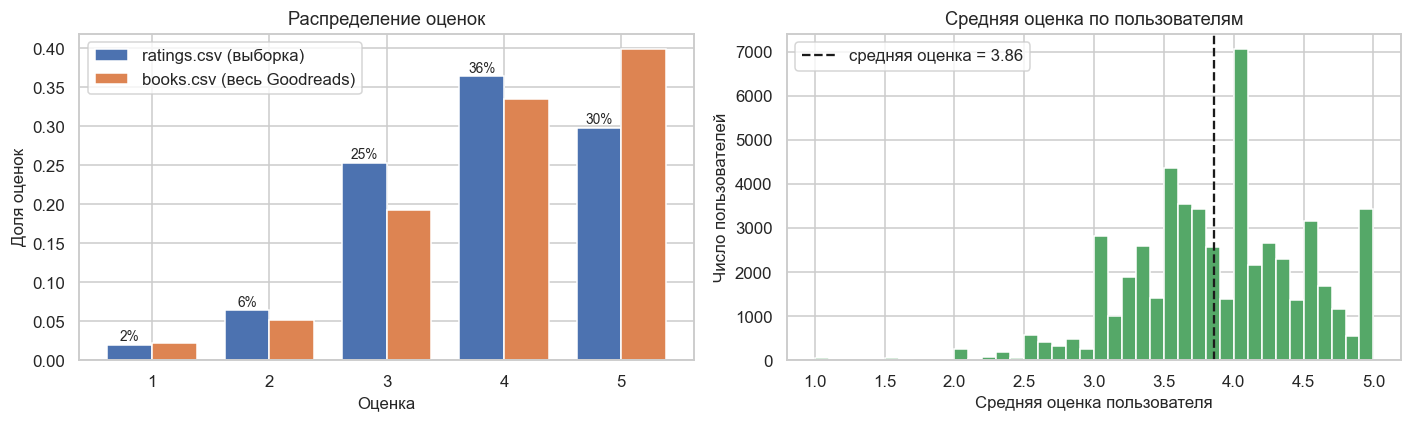

Среднее = 3.856, медиана = 4, доля оценок >= 4: 66.2%, доля оценок <= 2: 8.4%
Доля пользователей со средней оценкой > 4: 37.0%; доля ставивших только оценки >= 4: 22.0%


In [5]:
rating_share = ratings["rating"].value_counts(normalize=True).sort_index()
global_cnt = books_raw[[f"ratings_{i}" for i in range(1, 6)]].sum()
global_share = global_cnt / global_cnt.sum()
user_mean = ratings.groupby("u")["rating"].mean()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
x, w = np.arange(1, 6), 0.38
ax[0].bar(x - w / 2, rating_share.values, w, label="ratings.csv (выборка)")
ax[0].bar(x + w / 2, global_share.values, w, label="books.csv (весь Goodreads)")
for xi, v in zip(x, rating_share.values):
    ax[0].text(xi - w / 2, v + 0.005, f"{v:.0%}", ha="center", fontsize=9)
ax[0].set(xlabel="Оценка", ylabel="Доля оценок", title="Распределение оценок", xticks=x)
ax[0].legend()

ax[1].hist(user_mean, bins=40, color="C2", edgecolor="white")
ax[1].axvline(ratings["rating"].mean(), color="k", ls="--", label=f"средняя оценка = {ratings['rating'].mean():.2f}")
ax[1].set(xlabel="Средняя оценка пользователя", ylabel="Число пользователей",
          title="Средняя оценка по пользователям")
ax[1].legend()
plt.tight_layout(); plt.show()

print(f"Среднее = {ratings['rating'].mean():.3f}, медиана = {ratings['rating'].median():.0f}, "
      f"доля оценок >= 4: {(ratings['rating'] >= 4).mean():.1%}, доля оценок <= 2: {(ratings['rating'] <= 2).mean():.1%}")
print(f"Доля пользователей со средней оценкой > 4: {(user_mean > 4).mean():.1%}; "
      f"доля ставивших только оценки >= 4: {(ratings.groupby('u')['rating'].min() >= 4).mean():.1%}")

Оценки смещены вправо: 4 и 5 ставят в сумме около двух третей раз (66% оценок >= 4), а оценок 1-2 меньше 10%. Это обычное смещение явных оценок: люди оценивают то, что им в целом нравится. Из-за этого средняя оценка книги плохо различает книги, а у пользователей она сильно отличается (у 37% средняя выше 4), поэтому в моделях нужно учитывать смещения пользователя и книги. По этой же причине порог релевантности выбран равным 4: он отделяет «понравилось» от нейтральных оценок, а порог 5 выбросил бы слишком много сигнала.

## 1.3 Активность пользователей и холодный старт

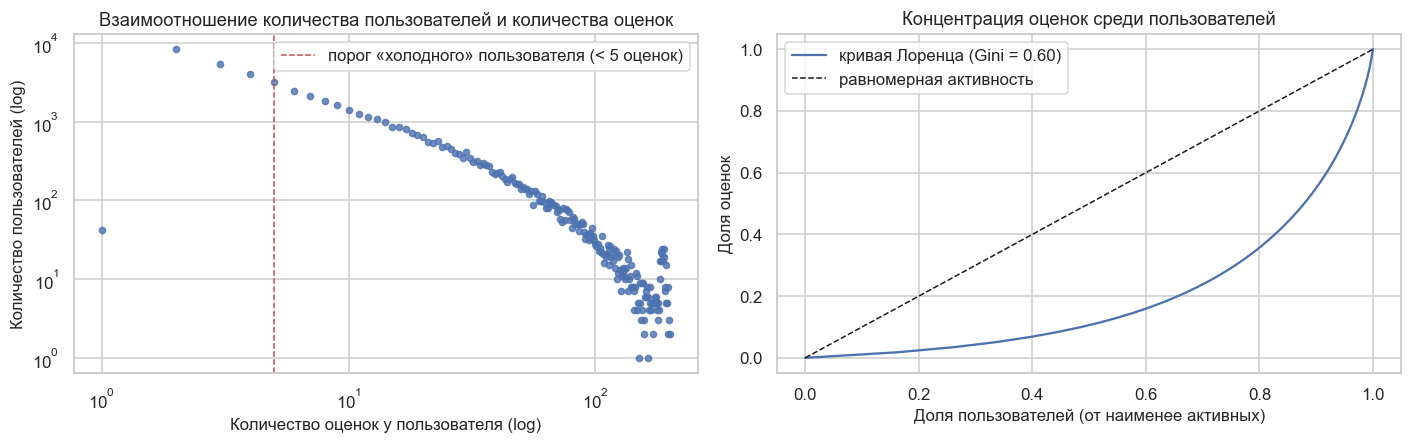

,пользователей,доля пользователей,оценок,доля оценок
1-4 (холодные),17765,0.3325,48873,0.0499
5-9,11285,0.2112,75215,0.0768
10-19,9762,0.1827,135178,0.1380
20-49,9704,0.1816,300912,0.3072
50+ (активные),4908,0.0919,419300,0.4281


count   53424.0000
mean       18.3000
std        26.2000
min         1.0000
25%         3.0000
50%         8.0000
75%        22.0000
max       200.0000


In [6]:
user_cnt = ratings.groupby("u").size()
users_by_cnt = user_cnt.value_counts().sort_index()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].loglog(users_by_cnt.index, users_by_cnt.values, "o", ms=4, alpha=0.8)
ax[0].axvline(5, color="r", ls="--", lw=1, label="порог «холодного» пользователя (< 5 оценок)")
ax[0].set(xlabel="Количество оценок у пользователя (log)", ylabel="Количество пользователей (log)",
          title="Взаимоотношение количества пользователей и количества оценок")
ax[0].legend()

s = np.sort(user_cnt.values)
share_users = np.arange(1, len(s) + 1) / len(s)
share_ratings = np.cumsum(s) / s.sum()
gini = 1 - 2 * np.trapz(share_ratings, share_users)
ax[1].plot(share_users, share_ratings, label=f"кривая Лоренца (Gini = {gini:.2f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=1, label="равномерная активность")
ax[1].set(xlabel="Доля пользователей (от наименее активных)", ylabel="Доля оценок",
          title="Концентрация оценок среди пользователей")
ax[1].legend()
plt.tight_layout(); plt.show()

bins = [0, 4, 9, 19, 49, 10**6]
labels = ["1-4 (холодные)", "5-9", "10-19", "20-49", "50+ (активные)"]
seg = pd.cut(user_cnt, bins=bins, labels=labels)
seg_tbl = pd.DataFrame({
    "пользователей": seg.value_counts().sort_index(),
    "доля пользователей": seg.value_counts(normalize=True).sort_index(),
    "оценок": user_cnt.groupby(seg).sum(),
})
seg_tbl["доля оценок"] = seg_tbl["оценок"] / seg_tbl["оценок"].sum()
display(seg_tbl)
print(user_cnt.describe().round(1).to_string())

Активность распределена неравномерно, хвост тяжёлый: медиана - 8 оценок, треть пользователей поставила 1-4 оценки, а 9% самых активных (50+ оценок) дают 43% всех оценок. Максимум ровно 200, то есть выборка усечена сверху.

Это холодный старт для пользователей: по трети пользователей (меньше 5 оценок) коллаборативные методы почти ничего не знают, им нужны неперсонализированные или контентные рекомендации.

## 1.4 Популярность книг и «длинный хвост»

В `ratings.csv` у каждой книги не более 100 оценок - это сэмпл. Поэтому «настоящий» длинный хвост виден по `books.csv::ratings_count`
(число оценок на Goodreads в целом). Построим оба графика.

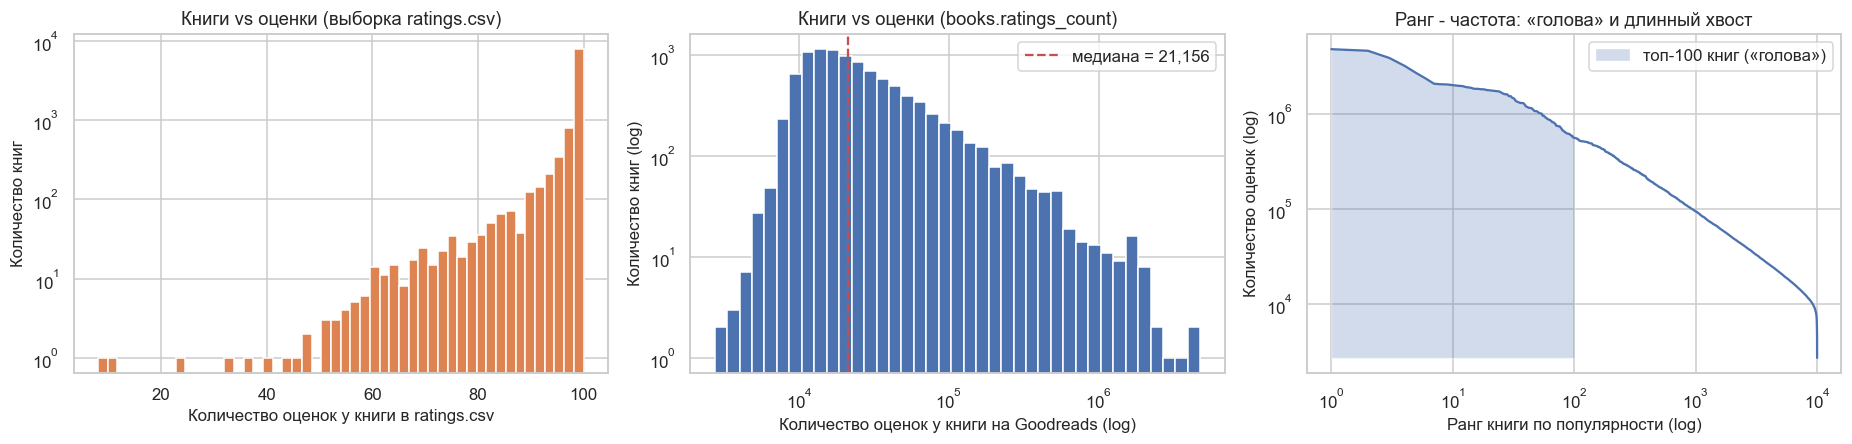

ratings.csv: у книги от 8 до 100 оценок, медиана 100 - плоское распределение из-за ограничения «<= 100 оценок на книгу».
books.csv: топ-1% книг (100 шт.) = 23.4% всех оценок, топ-10% = 57.1%, нижние 50% книг = 12.8%
Самая популярная книга: «The Hunger Games (The Hunger Games, #1)» (4,780,653 оценок), самая редкая из 10k: 2,716 оценок


In [7]:
book_cnt = ratings.groupby("i").size().reindex(range(ds.n_items), fill_value=0)
glob = ds.books["ratings_count"].to_numpy()

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].hist(book_cnt, bins=50, color="C1", edgecolor="white")
ax[0].set(xlabel="Количество оценок у книги в ratings.csv", ylabel="Количество книг",
          title="Книги vs оценки (выборка ratings.csv)", yscale="log")

log_bins = np.logspace(np.log10(glob.min()), np.log10(glob.max()), 40)
ax[1].hist(glob, bins=log_bins, color="C0", edgecolor="white")
ax[1].set(xscale="log", yscale="log", xlabel="Количество оценок у книги на Goodreads (log)",
          ylabel="Количество книг (log)", title="Книги vs оценки (books.ratings_count)")
ax[1].axvline(np.median(glob), color="r", ls="--", label=f"медиана = {np.median(glob):,.0f}")
ax[1].legend()

rank_sorted = np.sort(glob)[::-1]
ax[2].loglog(np.arange(1, len(rank_sorted) + 1), rank_sorted)
ax[2].fill_between(np.arange(1, 101), rank_sorted[:100], rank_sorted.min(), alpha=0.25, label="топ-100 книг («голова»)")
ax[2].set(xlabel="Ранг книги по популярности (log)", ylabel="Количество оценок (log)",
          title="Ранг - частота: «голова» и длинный хвост")
ax[2].legend()
plt.tight_layout(); plt.show()

cum = np.cumsum(rank_sorted) / rank_sorted.sum()
print(f"ratings.csv: у книги от {book_cnt.min()} до {book_cnt.max()} оценок, медиана {book_cnt.median():.0f} - "
      f"плоское распределение из-за ограничения «<= 100 оценок на книгу».")
print(f"books.csv: топ-1% книг ({int(0.01*len(glob))} шт.) = {cum[int(0.01*len(glob))-1]:.1%} всех оценок, "
      f"топ-10% = {cum[int(0.10*len(glob))-1]:.1%}, нижние 50% книг = {1 - cum[int(0.5*len(glob))-1]:.1%}")
print(f"Самая популярная книга: «{ds.books.loc[np.argmax(glob), 'title']}» ({glob.max():,} оценок), "
      f"самая редкая из 10k: {glob.min():,} оценок")

По глобальной статистике Goodreads хорошо виден длинный хвост: топ-1% книг собирает около 23% всех оценок, топ-10% - 57%, а нижняя половина каталога - всего 13%. Это смещение популярности: модель, обученная на сырых взаимодействиях, будет рекомендовать в основном «голову», а редкие и новые книги останутся незамеченными.

В самом `ratings.csv` картина другая: из-за ограничения «не больше 100 оценок на книгу» распределение плоское, и популярность внутри этой выборки почти ничего не говорит о выборе пользователя. Дальше это видно по Popularity: она не лучше случайной выдачи.

## 1.5 Теги книг

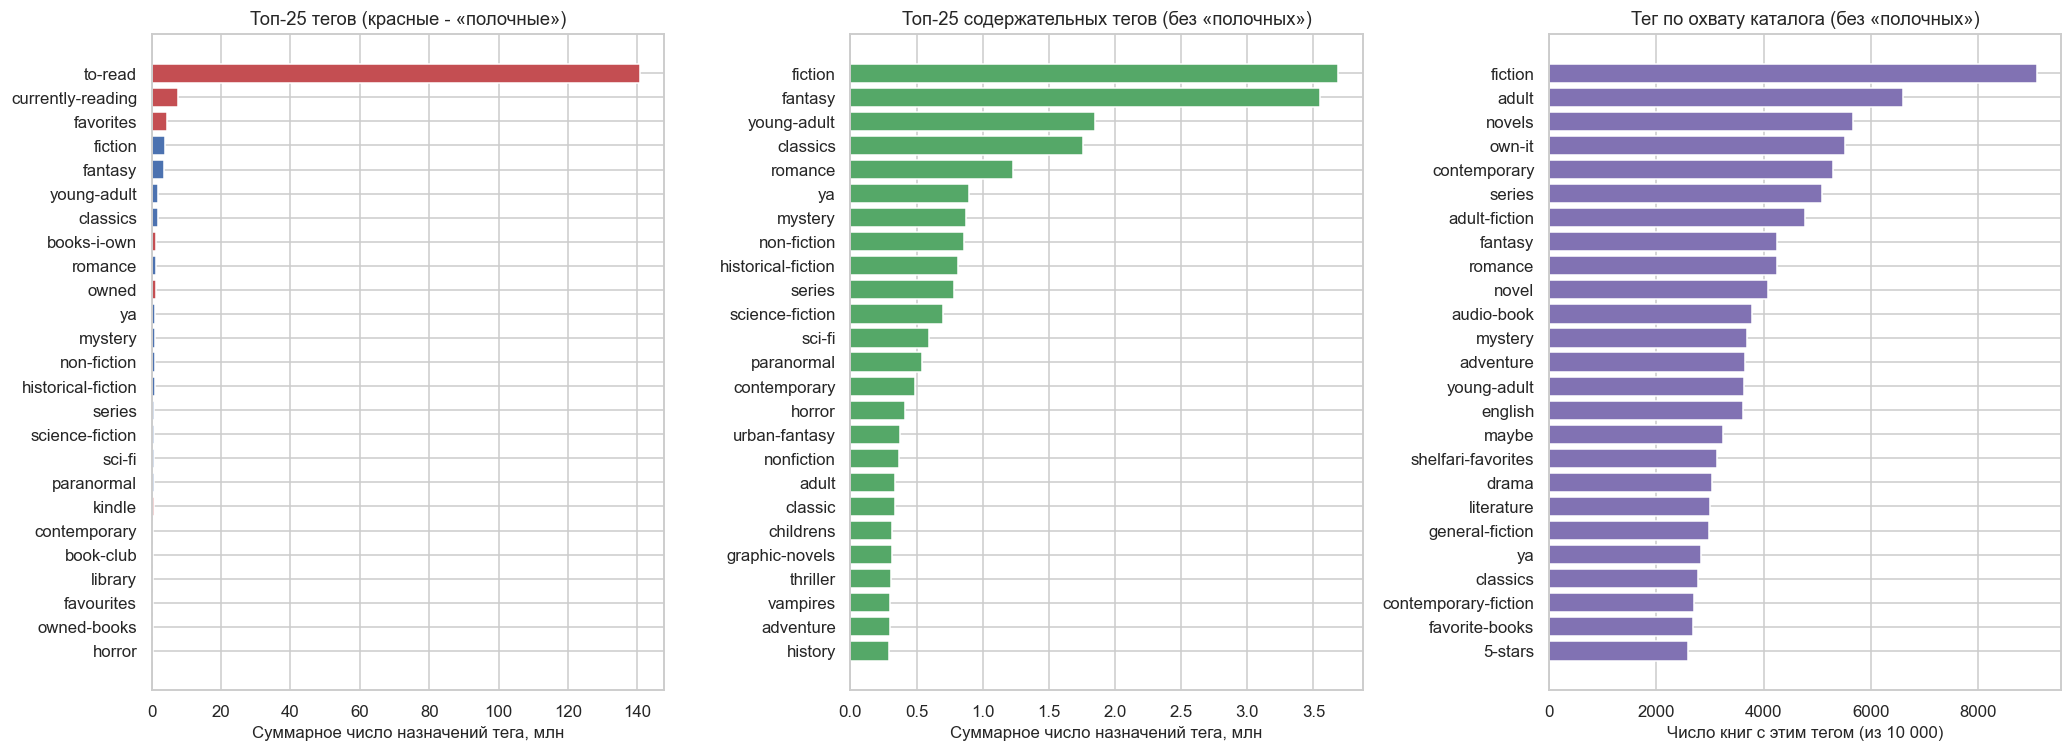

Всего уникальных тегов: 34,250; не более 100 тегов на книгу (топ по частоте), медиана 100
«Полочные» теги составляют 78.3% всех назначений тегов; только to-read - 67.4%


In [8]:
bt = ds.book_tags
tag_total = bt.groupby("tag_name")["count"].sum().sort_values(ascending=False)
is_shelf = tag_total.index.map(is_shelf_tag).to_numpy()
tag_books = bt.groupby("tag_name").size().sort_values(ascending=False)

fig, ax = plt.subplots(1, 3, figsize=(19, 7))
top_raw = tag_total.head(25)[::-1]
ax[0].barh(top_raw.index, top_raw.values / 1e6, color=["C3" if is_shelf_tag(t) else "C0" for t in top_raw.index])
ax[0].set(xlabel="Суммарное число назначений тега, млн", title="Топ-25 тегов (красные - «полочные»)")

top_clean = tag_total[~is_shelf].head(25)[::-1]
ax[1].barh(top_clean.index, top_clean.values / 1e6, color="C2")
ax[1].set(xlabel="Суммарное число назначений тега, млн", title="Топ-25 содержательных тегов (без «полочных»)")

top_books = tag_books[~tag_books.index.map(is_shelf_tag)].head(25)[::-1]
ax[2].barh(top_books.index, top_books.values, color="C4")
ax[2].set(xlabel="Число книг с этим тегом (из 10 000)", title="Тег по охвату каталога (без «полочных»)")
plt.tight_layout(); plt.show()

print(f"Всего уникальных тегов: {bt['tag_id'].nunique():,}; не более 100 тегов на книгу (топ по частоте), "
      f"медиана {bt.groupby('goodreads_book_id').size().median():.0f}")
print(f"«Полочные» теги составляют {tag_total[is_shelf].sum() / tag_total.sum():.1%} всех назначений тегов; "
      f"только to-read - {tag_total['to-read'] / tag_total.sum():.1%}")

Около 78% всех назначений тегов приходится на служебные «полки» (`to-read`, `currently-reading`, `favorites`, `owned` и т.п.). Они описывают действия читателя, а не содержание книги, для контентной модели это шум, поэтому такие теги отфильтрованы. Среди остальных самые частые - жанры и темы (`fiction`, `fantasy`, `young-adult`, `classics`, `romance`, `mystery`, `non-fiction`, `science-fiction`), их и используем в профиле книги.

## 1.6 Разреженность матрицы

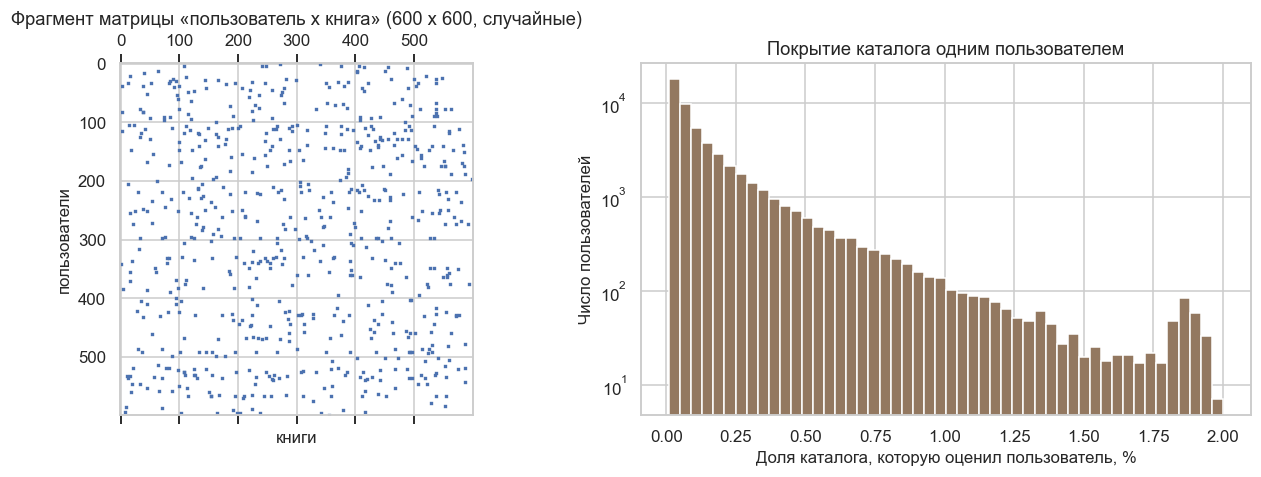

Пользователь в среднем видел 0.183% каталога; максимум - 2.00%.


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sub_u = rng.choice(ds.n_users, 600, replace=False)
sub_i = rng.choice(ds.n_items, 600, replace=False)
R_full = to_csr(ratings, ds.shape, value=None)
ax[0].spy(R_full[sub_u][:, sub_i], markersize=1.2, color="C0")
ax[0].set(title="Фрагмент матрицы «пользователь x книга» (600 x 600, случайные)",
          xlabel="книги", ylabel="пользователи")

dens = R_full.getnnz(axis=1)
ax[1].hist(dens / ds.n_items * 100, bins=50, color="C5", edgecolor="white")
ax[1].set(xscale="linear", yscale="log", xlabel="Доля каталога, которую оценил пользователь, %",
          ylabel="Число пользователей", title="Покрытие каталога одним пользователем")
plt.tight_layout(); plt.show()
print(f"Пользователь в среднем видел {dens.mean() / ds.n_items:.3%} каталога; максимум - {dens.max() / ds.n_items:.2%}.")

## 1.7 Основные проблемы данных

- Разреженность. Заполнено около 0.18% матрицы (в среднем 18 оценок на пользователя из 10 000 книг). У пар книг мало общих читателей, поэтому схожести по оценкам шумные: нужны shrinkage, ограничение числа соседей или низкоранговые методы.
- Смещение популярности и длинный хвост. По глобальной статистике небольшая «голова» собирает большую часть оценок, хвост почти не оценён. Средний рейтинг без порога по числу оценок поощряет книги с одной-двумя пятёрками.
- Холодный старт. У трети пользователей 1-4 оценки, а у новых книг оценок нет вовсе.
- Смещение в сторону высоких оценок: две трети оценок >= 4, у разных пользователей разная средняя оценка.
- Особенности самих данных: дубли пар (user, book), разные ключи `id` и `book_id`, пропуски в `original_title`, шумные «полочные» теги, усечение выборки (не больше 200 оценок на пользователя и 100 на книгу) и отсутствие временных меток. Из-за последнего разбиение делаем случайным, а не по времени.
- Пропущенные оценки не случайны: пользователь оценивает то, что прочитал, и то, какие книги он оценил, само по себе сильный сигнал. Это влияет на результаты этапа 5.

# Протокол оценки: разбиение данных

Временных меток нет, поэтому делим данные случайно внутри каждого пользователя (`split_per_user`): 20% его оценок (минимум одна) идёт в тест, остальное в train. Каждый пользователь с двумя и более оценками есть в обеих частях, так что холодных пользователей в тесте нет. Холодные книги смоделируем отдельно на этапе 6.

Чтобы не подбирать гиперпараметры на тесте, выделяем три части:
- train (около 70%) - обучение при подборе гиперпараметров; val (около 10%) - выбор гиперпараметров и весов гибрида;
- trainval = train + val - финальное обучение; test (20%) - итоговая оценка.

Релевантной считаем книгу, которой пользователь в отложенной части поставил оценку >= 4. Кандидаты для рекомендаций - все книги, которых нет в обучающей части пользователя. В усреднение метрик входят пользователи, у которых в отложенной части есть хотя бы одна релевантная книга.

In [10]:
trainval_df, test_df = split_per_user(ratings, 0.20, seed=SEED)
train_df, val_df = split_per_user(trainval_df, 0.125, seed=SEED + 1)   # 0.8 * 0.125 = 10% от всех оценок

R_train = to_csr(train_df, ds.shape)
R_trainval = to_csr(trainval_df, ds.shape)

split_tbl = pd.DataFrame({
    "оценок": [len(train_df), len(val_df), len(trainval_df), len(test_df)],
    "доля": [len(d) / n_ratings for d in (train_df, val_df, trainval_df, test_df)],
    "релевантных (>=4)": [(d["rating"] >= LIKE_THRESHOLD).sum() for d in (train_df, val_df, trainval_df, test_df)],
    "пользователей": [d["u"].nunique() for d in (train_df, val_df, trainval_df, test_df)],
}, index=["train", "val", "trainval", "test"])
display(split_tbl)
print("Пользователей с >= 1 релевантной книгой: val -", val_df[val_df.rating >= 4]["u"].nunique(),
      "| test -", test_df[test_df.rating >= 4]["u"].nunique())
assert not set(zip(trainval_df.u, trainval_df.i)) & set(zip(test_df.u, test_df.i)), "утечка train -> test!"

,оценок,доля,релевантных (>=4),пользователей
train,670163,0.6842,443158,53424
val,106043,0.1083,70692,45071
trainval,776206,0.7925,513850,53424
test,203272,0.2075,134805,53382


Пользователей с >= 1 релевантной книгой: val - 34906 | test - 43434


# Метрики и функция оценки

Эти функции нужны уже при подборе гиперпараметров на этапе 2, поэтому определяем их сразу после разбиения. Формулы метрик приведены в начале этапа 5.

Все модели ниже наследуются от `Recommender` и умеют одно: `score(users)` возвращает матрицу скоров `(число пользователей, число книг)`. Исключение уже оценённых книг, выбор top-N и подсчёт метрик сделаны один раз для всех моделей.

In [11]:
def top_k(scores: np.ndarray, k: int) -> np.ndarray:
    """Индексы k лучших элементов в каждой строке (по убыванию скора)."""
    k = min(k, scores.shape[1])
    part = np.argpartition(-scores, k - 1, axis=1)[:, :k]          # O(n), без полной сортировки
    order = np.argsort(-np.take_along_axis(scores, part, axis=1), axis=1, kind="stable")
    return np.take_along_axis(part, order, axis=1)


def mask_seen(scores: np.ndarray, seen: sparse.spmatrix | None) -> np.ndarray:
    """Ставит -inf для книг, которые пользователь уже оценил (меняет массив на месте)."""
    if seen is not None:
        coo = seen.tocoo()
        scores[coo.row, coo.col] = -np.inf
    return scores


def zscore(scores: np.ndarray) -> np.ndarray:
    """Стандартизация скоров каждого пользователя (по строкам)."""
    mean = scores.mean(axis=1, keepdims=True)
    std = scores.std(axis=1, keepdims=True)
    return (scores - mean) / np.where(std > 0, std, 1.0)


def ranking_metrics(hits: np.ndarray, n_relevant: np.ndarray, ks: tuple[int, ...]) -> dict[str, np.ndarray]:
    """Precision@K, Recall@K и nDCG@K для каждого пользователя.

    hits[u, r] - релевантна ли книга на позиции r (с нуля) в выдаче пользователя u,
    n_relevant[u] - число релевантных книг пользователя в тесте (больше нуля).
    """
    hits = hits.astype(np.float64)
    discounts = 1.0 / np.log2(np.arange(2, hits.shape[1] + 2))      # 1 / log2(позиция + 1)
    ideal_cum = np.cumsum(discounts)
    out = {}
    for k in ks:
        h = hits[:, :k]
        n_hit = h.sum(axis=1)
        dcg = (h * discounts[:k]).sum(axis=1)
        idcg = ideal_cum[np.minimum(k, n_relevant) - 1]             # идеальная выдача
        out[f"P@{k}"] = n_hit / k
        out[f"R@{k}"] = n_hit / n_relevant
        out[f"nDCG@{k}"] = dcg / idcg
    return out


def rmse(pred, true) -> float:
    return float(np.sqrt(np.mean((np.asarray(pred, dtype=np.float64) - np.asarray(true, dtype=np.float64)) ** 2)))


class Recommender(ABC):
    name: str = "model"

    @abstractmethod
    def score(self, users: np.ndarray) -> np.ndarray:
        """Матрица скоров (len(users), n_items): чем больше, тем выше книга в выдаче."""

    def recommend(self, users: np.ndarray, n: int = 10, seen: sparse.csr_matrix | None = None) -> np.ndarray:
        """Индексы top-n книг, которых пользователь ещё не оценил."""
        users = np.asarray(users)
        scores = np.array(self.score(users), dtype=np.float32)
        mask_seen(scores, None if seen is None else seen[users])
        return top_k(scores, n)


@dataclass
class EvalResult:
    summary: pd.Series      # метрики, усреднённые по пользователям
    per_user: pd.DataFrame  # метрики каждого пользователя


def evaluate_ranking(model, train: sparse.csr_matrix, test_df: pd.DataFrame,
                     ks: tuple[int, ...] = (5, 10, 20), threshold: float = LIKE_THRESHOLD,
                     users: np.ndarray | None = None, candidates: np.ndarray | None = None,
                     batch_size: int = 2000) -> EvalResult:
    """Считает Precision/Recall/nDCG@K.

    Релевантные книги пользователя - его оценки в test_df не ниже threshold. Кандидаты -
    все книги, которых нет в train (или только candidates). Усредняем по пользователям,
    у которых есть хотя бы одна релевантная книга. Дополнительно считаем coverage@K
    (доля каталога, попавшая в чьи-то выдачи) и avg_pop@K (среднее число train-оценок у
    рекомендованных книг).
    """
    n_users, n_items = train.shape
    rel = to_csr(test_df[test_df["rating"] >= threshold], train.shape, value=None, dtype=np.int8)
    rel_counts = np.asarray(rel.sum(axis=1)).ravel()
    eval_users = np.flatnonzero(rel_counts > 0)
    if users is not None:
        eval_users = np.intersect1d(eval_users, users)

    allowed = None
    if candidates is not None:
        allowed = np.zeros(n_items, dtype=bool)
        allowed[candidates] = True

    k_max = max(ks)
    recs, metrics = [], {}
    for start in range(0, len(eval_users), batch_size):
        batch = eval_users[start:start + batch_size]
        scores = np.array(model.score(batch), dtype=np.float32)    # копия, дальше пишем в неё
        mask_seen(scores, train[batch])
        if allowed is not None:
            scores[:, ~allowed] = -np.inf
        rec = top_k(scores, k_max)
        hits = np.take_along_axis(rel[batch].toarray(), rec, axis=1).astype(bool)
        for name, values in ranking_metrics(hits, rel_counts[batch], ks).items():
            metrics.setdefault(name, []).append(values)
        recs.append(rec)

    recs = np.vstack(recs)
    per_user = pd.DataFrame({k: np.concatenate(v) for k, v in metrics.items()}, index=eval_users)
    per_user.index.name = "u"
    per_user["n_train"] = np.asarray(train[eval_users].getnnz(axis=1)).ravel()

    summary = per_user.drop(columns="n_train").mean()
    item_pop = np.asarray(train.getnnz(axis=0)).ravel()
    n_cand = n_items if candidates is None else len(candidates)
    for k in ks:
        summary[f"coverage@{k}"] = len(np.unique(recs[:, :k])) / n_cand
        summary[f"avg_pop@{k}"] = item_pop[recs[:, :k]].mean()
    summary["n_users"] = len(eval_users)
    return EvalResult(summary, per_user)


def results_table(results: dict[str, EvalResult], columns: list[str]) -> pd.DataFrame:
    """Сводная таблица: строки - модели, колонки - выбранные метрики."""
    return pd.DataFrame({name: r.summary for name, r in results.items()}).T[columns]

In [12]:
# Проверка метрик на примерах, посчитанных вручную
# В выдаче из 3 книг релевантные стоят на 1 и 3 месте, всего у пользователя 4 релевантных
m = ranking_metrics(np.array([[1, 0, 1]], dtype=bool), np.array([4]), ks=(1, 3))
dcg = 1 / np.log2(2) + 1 / np.log2(4)
idcg = 1 / np.log2(2) + 1 / np.log2(3) + 1 / np.log2(4)           # три релевантные сверху
assert np.isclose(m["P@3"][0], 2 / 3) and np.isclose(m["R@3"][0], 2 / 4)
assert np.isclose(m["nDCG@3"][0], dcg / idcg) and np.isclose(m["nDCG@1"][0], 1.0)

# nDCG зависит от порядка, Precision - нет
first = ranking_metrics(np.array([[1, 0, 0]], dtype=bool), np.array([1]), ks=(3,))
last = ranking_metrics(np.array([[0, 0, 1]], dtype=bool), np.array([1]), ks=(3,))
assert np.isclose(first["nDCG@3"][0], 1.0) and np.isclose(last["nDCG@3"][0], 0.5)
assert first["P@3"][0] == last["P@3"][0]


# evaluate_ranking: книга из train не попадает в выдачу, порог релевантности работает
class FixedScores(Recommender):
    def __init__(self, scores):
        self.scores = scores

    def score(self, users):
        return self.scores[users]


train_toy = sparse.csr_matrix(np.array([[5, 0, 0, 0, 0]], dtype=np.float32))
test_toy = pd.DataFrame({"u": [0, 0], "i": [1, 2], "rating": [5, 3]})   # релевантна только книга 1
res = evaluate_ranking(FixedScores(np.array([[100, 9, 5, 4, 3]], dtype=np.float32)), train_toy, test_toy, ks=(1, 2))
assert res.summary["P@1"] == 1.0 and res.summary["nDCG@2"] == 1.0       # книга 0 исключена
res = evaluate_ranking(FixedScores(np.array([[100, 1, 5, 4, 3]], dtype=np.float32)), train_toy, test_toy, ks=(1, 2))
assert res.summary["P@1"] == 0.0 and res.summary["R@2"] == 0.0
print("метрики совпадают с ручным расчётом")

метрики совпадают с ручным расчётом


# Этап 2. Базовые и контентные модели

## 2.1 Неперсонализированная модель (Popularity)

Рекомендуем топ-N книг по средней оценке среди книг, у которых не меньше `min_ratings` оценок: книга с одной пятёркой не должна обгонять книгу с тысячей оценок и средней 4.5. Для сравнения добавлены байесовский рейтинг (как в IMDb) и просто число оценок. Порог выбираем на val по nDCG@10.

Код популярных моделей. `PopularityRecommender` строит одинаковый топ для всех пользователей, `RandomRecommender` нужен как нижняя граница для сравнения.

In [13]:
class PopularityRecommender(Recommender):
    """Одинаковый топ для всех.

    mean_rating - средняя оценка среди книг, у которых не меньше min_ratings оценок;
    bayesian - взвешенный рейтинг как в IMDb: (v*R + m*C) / (v + m);
    count - число оценок.
    """

    def __init__(self, strategy: str = "mean_rating", min_ratings: int = 50):
        assert strategy in {"mean_rating", "bayesian", "count"}
        self.strategy, self.min_ratings = strategy, min_ratings
        self.name = f"Popularity ({strategy})"

    def fit(self, train: sparse.csr_matrix) -> "PopularityRecommender":
        """train - матрица пользователь x книга с оценками (0 - нет оценки)."""
        counts = np.asarray(train.getnnz(axis=0)).ravel().astype(np.float64)
        sums = np.asarray(train.sum(axis=0)).ravel().astype(np.float64)
        self.counts_ = counts
        self.means_ = np.divide(sums, counts, out=np.zeros_like(sums), where=counts > 0)
        if self.strategy == "mean_rating":
            self.scores_ = np.where(counts >= self.min_ratings, self.means_, 0.0)   # 0 меньше любой оценки
        elif self.strategy == "bayesian":
            c_global = sums.sum() / counts.sum()
            self.scores_ = (sums + self.min_ratings * c_global) / (counts + self.min_ratings)
        else:
            self.scores_ = counts
        return self

    def score(self, users: np.ndarray) -> np.ndarray:
        return np.broadcast_to(self.scores_.astype(np.float32), (len(users), len(self.scores_)))

    def top_n(self, n: int, books: pd.DataFrame) -> pd.DataFrame:
        idx = np.argsort(-self.scores_, kind="stable")[:n]
        out = books.loc[idx, ["book_id", "title", "authors"]].copy()
        out["mean_rating"] = self.means_[idx]
        out["n_ratings"] = self.counts_[idx].astype(int)
        return out.reset_index(drop=True)


class RandomRecommender(Recommender):
    name = "Random"

    def __init__(self, seed: int = 0):
        self.seed = seed

    def fit(self, train: sparse.csr_matrix) -> "RandomRecommender":
        self.n_items = train.shape[1]
        return self

    def score(self, users: np.ndarray) -> np.ndarray:
        return np.random.default_rng(self.seed).random((len(users), self.n_items), dtype=np.float32)

In [14]:
pop_grid = [("mean_rating", m) for m in (1, 10, 25, 40, 55)] + [("bayesian", m) for m in (10, 50)] + [("count", 0)]
rows = []
for strategy, m in pop_grid:
    model = PopularityRecommender(strategy, m).fit(R_train)
    res = evaluate_ranking(model, R_train, val_df, ks=(K_MAIN,))
    rows.append({"стратегия": strategy, "min_ratings / вес": m, "P@10": res.summary["P@10"],
                 "R@10": res.summary["R@10"], "nDCG@10": res.summary["nDCG@10"]})
pop_tbl = pd.DataFrame(rows)
display(pop_tbl)

# nDCG у разных порогов различается в 4-м знаке (это шум), поэтому берём самый консервативный порог
# из тех, что не хуже 95% от лучшего значения
mr = pop_tbl[pop_tbl["стратегия"] == "mean_rating"]
ok = mr[mr["nDCG@10"] >= 0.95 * mr["nDCG@10"].max()]
POP_PARAMS = dict(strategy="mean_rating", min_ratings=int(ok["min_ratings / вес"].max()))
print("Выбрано:", POP_PARAMS)

,стратегия,min_ratings / вес,P@10,R@10,nDCG@10
0,mean_rating,1,0.0003,0.0016,0.0008
1,mean_rating,10,0.0003,0.0016,0.0008
2,mean_rating,25,0.0003,0.0016,0.0008
3,mean_rating,40,0.0003,0.0016,0.0008
4,mean_rating,55,0.0002,0.0012,0.0007
5,bayesian,10,0.0002,0.0015,0.0007
6,bayesian,50,0.0002,0.0012,0.0007
7,count,0,0.0001,0.0002,0.0001


Выбрано: {'strategy': 'mean_rating', 'min_ratings': 40}


In [15]:
pop_final = PopularityRecommender(**POP_PARAMS).fit(R_trainval)
display(pop_final.top_n(10, ds.books))

,book_id,title,authors,mean_rating,n_ratings
0,7947,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem",4.8387,62
1,6920,The Indispensable Calvin and Hobbes,Bill Watterson,4.8077,78
2,5207,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson,4.8052,77
3,3275,"Harry Potter Boxed Set, Books 1-5 (Harry Potte...","J.K. Rowling, Mary GrandPré",4.7907,86
4,6361,There's Treasure Everywhere: A Calvin and Hobb...,Bill Watterson,4.7848,79
5,9566,Attack of the Deranged Mutant Killer Monster S...,Bill Watterson,4.7816,87
6,8978,The Revenge of the Baby-Sat,Bill Watterson,4.7632,76
7,4483,It's a Magical World: A Calvin and Hobbes Coll...,Bill Watterson,4.7403,77
8,3753,"Harry Potter Collection (Harry Potter, #1-6)",J.K. Rowling,4.7375,80
9,1308,A Court of Mist and Fury (A Court of Thorns an...,Sarah J. Maas,4.7237,76


Порог нужен, чтобы в топ не попадали книги с малым числом оценок и «идеальным» средним. Метрики Popularity при этом близки к случайным: в этом датасете популярность малоинформативна (см. EDA), подробнее разберём на этапе 5.

## 2.2 Контентная модель: TF-IDF по названию и тегам

Профиль книги - это `original_title` (если он пуст, то `title` без суффикса «(Series, #1)») плюс список тегов. Для тегов объединяем `book_tags` и `tags`, выбрасываем «полочные», берём 30 самых частых тегов книги и склеиваем составные теги в один токен (`science-fiction -> science_fiction`). Каждый тег повторяется от 1 до 5 раз пропорционально его частоте внутри книги, чтобы TF-IDF (с сублинейным TF) учитывал вес тега.

Код контентной модели: функция `build_book_profiles` собирает текстовые профили, `ContentBasedRecommender` считает TF-IDF и косинусную близость.

In [16]:
def build_book_profiles(books: pd.DataFrame, book_tags: pd.DataFrame,
                        max_tags: int = 30, max_repeat: int = 5) -> pd.Series:
    """Текстовый профиль книги: original_title + теги."""
    # если original_title пуст, берём title без суффикса "(Series, #1)"
    title = books["original_title"].fillna(books["title"].str.replace(r"\s*\(.*\)\s*$", "", regex=True))

    tags = book_tags[~book_tags["tag_name"].fillna("").map(is_shelf_tag)].copy()
    tags = tags.sort_values(["goodreads_book_id", "count"], ascending=[True, False])
    tags = tags.groupby("goodreads_book_id").head(max_tags)               # самые частые теги книги
    peak = tags.groupby("goodreads_book_id")["count"].transform("max")
    repeat = np.ceil(max_repeat * tags["count"] / peak).astype(int)      # популярный тег повторяем чаще
    token = tags["tag_name"].str.lower().str.replace(r"[^0-9a-z]+", "_", regex=True).str.strip("_")
    tags["text"] = [" ".join([t] * r) for t, r in zip(token, repeat)]
    tag_text = tags.groupby("goodreads_book_id")["text"].agg(" ".join)

    tag_text = books["goodreads_book_id"].map(tag_text).fillna("")
    return (title.fillna("") + " " + tag_text).str.lower()


class ContentBasedRecommender(Recommender):
    """TF-IDF по профилям книг. Для рекомендаций профиль пользователя - сумма векторов понравившихся книг."""

    name = "Content-based (TF-IDF)"

    def __init__(self, like_threshold: float = 4, **vectorizer_kwargs):
        self.like_threshold = like_threshold
        params = dict(stop_words="english", sublinear_tf=True, min_df=2)
        params.update(vectorizer_kwargs)
        self.vectorizer = TfidfVectorizer(**params)

    def fit_items(self, books: pd.DataFrame, book_tags: pd.DataFrame) -> "ContentBasedRecommender":
        self.books = books
        self.profiles = build_book_profiles(books, book_tags)
        self.tfidf = self.vectorizer.fit_transform(self.profiles).astype(np.float32).tocsr()   # строки нормированы
        return self

    def fit(self, train: sparse.csr_matrix) -> "ContentBasedRecommender":
        """Запоминает лайки пользователей (оценка >= порога) для построения их профилей."""
        self.likes_ = (train >= self.like_threshold).astype(np.float32).tocsr()
        return self

    def get_similar_books(self, book_id: int, N: int = 5) -> pd.DataFrame:
        """N книг, ближайших к book_id по косинусу TF-IDF-векторов."""
        item = int(self.books.index[self.books["book_id"] == book_id][0])
        sims = (self.tfidf @ self.tfidf[item].T).toarray().ravel()    # строки нормированы, значит это косинус
        sims[item] = -np.inf
        idx = np.argsort(-sims, kind="stable")[:N]
        out = self.books.loc[idx, ["book_id", "title", "authors"]].copy()
        out["similarity"] = sims[idx]
        return out.reset_index(drop=True)

    def score(self, users: np.ndarray) -> np.ndarray:
        profile = (self.likes_[users] @ self.tfidf).toarray()         # (пользователи, термины)
        norm = np.linalg.norm(profile, axis=1, keepdims=True)
        profile /= np.where(norm > 0, norm, 1.0)
        return np.asarray(self.tfidf @ profile.T).T                   # (пользователи, книги)

In [17]:
content = ContentBasedRecommender().fit_items(ds.books, ds.book_tags)
print("TF-IDF матрица:", content.tfidf.shape, f"| плотность {content.tfidf.nnz / np.prod(content.tfidf.shape):.2%}")
print("\nПример профиля (книга i=0):")
print(ds.books.loc[0, "title"], "->", content.profiles.iloc[0][:350], "...")

def get_similar_books(book_id: int, N: int = 5) -> pd.DataFrame:
    # N самых похожих книг по косинусной близости TF-IDF-векторов
    return content.get_similar_books(book_id, N)

def book_id_by_title(prefix: str) -> int:
    return int(ds.books.loc[ds.books["title"].str.startswith(prefix), "book_id"].iloc[0])

for title in ["The Hunger Games", "Harry Potter and the Sorcerer's Stone", "Pride and Prejudice", "The Da Vinci Code"]:
    bid = book_id_by_title(title)
    display(Markdown(f"**Похожие на «{ds.books.set_index('book_id').loc[bid, 'title']}»** (`book_id={bid}`)"))
    display(get_similar_books(bid, N=5))

TF-IDF матрица: (10000, 9289) | плотность 0.34%

Пример профиля (книга i=0):
The Hunger Games (The Hunger Games, #1) -> the hunger games young_adult young_adult young_adult young_adult young_adult fiction fiction fiction dystopian dystopian dystopian dystopia dystopia dystopia fantasy fantasy fantasy ya ya ya science_fiction science_fiction sci_fi sci_fi series romance adventure hunger_games teen post_apocalyptic the_hunger_games favorite_books action suzanne_collin ...


**Похожие на «The Hunger Games (The Hunger Games, #1)»** (`book_id=1`)

,book_id,title,authors,similarity
0,507,The Hunger Games Trilogy Boxset (The Hunger Ga...,Suzanne Collins,0.8787
1,20,"Mockingjay (The Hunger Games, #3)",Suzanne Collins,0.8757
2,17,"Catching Fire (The Hunger Games, #2)",Suzanne Collins,0.8215
3,6224,The World of the Hunger Games (Hunger Games Tr...,Kate Egan,0.6453
4,1820,"Hunger (Gone, #2)",Michael Grant,0.6239


**Похожие на «Harry Potter and the Sorcerer's Stone (Harry Potter, #1)»** (`book_id=2`)

,book_id,title,authors,similarity
0,18,Harry Potter and the Prisoner of Azkaban (Harr...,"J.K. Rowling, Mary GrandPré, Rufus Beck",0.8792
1,24,Harry Potter and the Goblet of Fire (Harry Pot...,"J.K. Rowling, Mary GrandPré",0.8514
2,23,Harry Potter and the Chamber of Secrets (Harry...,"J.K. Rowling, Mary GrandPré",0.7847
3,25,Harry Potter and the Deathly Hallows (Harry Po...,"J.K. Rowling, Mary GrandPré",0.7422
4,27,Harry Potter and the Half-Blood Prince (Harry ...,"J.K. Rowling, Mary GrandPré",0.7363


**Похожие на «Pride and Prejudice»** (`book_id=10`)

,book_id,title,authors,similarity
0,171,Emma,"Jane Austen, Fiona Stafford",0.7316
1,230,Persuasion,"Jane Austen, James Kinsley, Deidre Shauna Lynch",0.7113
2,451,Northanger Abbey,"Jane Austen, Alfred MacAdam",0.6190
3,471,Mansfield Park,"Jane Austen, Kathryn Sutherland, Tony Tanner, ...",0.6156
4,63,Wuthering Heights,"Emily Brontë, Richard J. Dunn",0.5717


**Похожие на «The Da Vinci Code (Robert Langdon, #2)»** (`book_id=26`)

,book_id,title,authors,similarity
0,4496,Angels and Demons / The Da Vinci Code (Robert ...,Dan Brown,0.6800
1,9,"Angels & Demons (Robert Langdon, #1)",Dan Brown,0.6162
2,201,"The Lost Symbol (Robert Langdon, #3)",Dan Brown,0.5816
3,145,Deception Point,Dan Brown,0.5089
4,170,Digital Fortress,Dan Brown,0.4673


Рекомендации выглядят осмысленно: к «Голодным играм» подтягиваются другие книги серии и антиутопии, к «Гарри Поттеру» - остальные части и юношеское фэнтези, к «Гордости и предубеждению» - другие романы Остин. Контентная модель не использует оценки, поэтому работает и для новых книг, и это её главное преимущество. Слабое место: она рекомендует только то, что похоже по тексту, и ничего не знает о качестве книги и вкусах читателей.

Для оценки на этапе 5 сделаем её персональной: профиль пользователя - сумма TF-IDF-векторов понравившихся ему книг (оценка >= 4), скор книги - косинус с этим профилем (`ContentBasedRecommender.score`).

# Этап 3. Item-based коллаборативная фильтрация

## 3.1 Матрица «пользователь x книга»

Матрицу храним в разреженном формате CSR: плотная 53 424 x 10 000 в float32 занимала бы около 2.1 ГБ, разреженная - несколько МБ. Используем два представления:
- explicit: оценки, центрированные по среднему пользователя. Косинус центрированных векторов - это adjusted cosine (по смыслу корреляция Пирсона по пользователям). Нужен для предсказания оценок.
- implicit: 1, если оценка >= 4, иначе 0, обычный косинус. Нужен для top-N.

In [18]:
dense_gb = ds.n_users * ds.n_items * 4 / 1e9
sparse_mb = (R_trainval.data.nbytes + R_trainval.indices.nbytes + R_trainval.indptr.nbytes) / 1e6
print(f"Плотная матрица: {dense_gb:.2f} ГБ; CSR: {sparse_mb:.1f} МБ (в {dense_gb * 1e3 / sparse_mb:.0f} раз меньше)")

Плотная матрица: 2.14 ГБ; CSR: 6.4 МБ (в 333 раз меньше)


## 3.2 Реализация

Реализация - класс `ItemBasedCF` в ячейке ниже.

1. Схожесть книг: `sim(i, j) = cos(x_i, x_j) * n_ij / (n_ij + lambda)`, где `n_ij` - число пользователей, оценивших обе книги, а `lambda` (shrinkage) уменьшает схожесть пар с 2-3 общими читателями. Считаем блоками по 500 книг через произведение разреженных матриц и из каждой строки оставляем только K лучших соседей, поэтому итоговая матрица `S` разреженная (10 000 x K вместо 10 000 x 10 000).
2. Предсказание оценки для пары (пользователь u, книга i): усредняем оценки пользователя по K ближайшим к i книгам, которые он оценил, с весами по схожести. Усредняем не сами оценки, а их отклонения от базовой оценки $b_{uj} = \bar r_u + d_j$ (среднее пользователя плюс смещение книги):
   $\hat r_{ui} = b_{ui} + \dfrac{\sum_{j \in N_K(i)} s_{ij}\,(r_{uj} - b_{uj})}{\sum_{j \in N_K(i)} s_{ij} + \lambda}$, где $\lambda$ - демпфирование (сжатие к базовой оценке, когда соседи слабые).
   Если пользователь не оценил ни одного из K соседей, возвращается базовая оценка $b_{ui}$.
3. Ранжирование для top-N (implicit): $\text{score}(u,i) = \sum_{j \in N_K(i)} s_{ij}\, x_{uj}$. Для всех пользователей и книг сразу это одно произведение разреженных матриц `X * S^T`, без циклов по парам.

In [19]:
class ItemBasedCF(Recommender):
    """Item-based CF: top-K соседей для каждой книги, shrinkage, предсказание оценок с демпфированием.

    feedback="explicit": вектор книги - оценки, центрированные по среднему пользователя
    (косинус таких векторов - adjusted cosine); используется для предсказания оценок.
    feedback="implicit": вектор книги - 1, если оценка >= порога, иначе 0; используется для top-N.
    """

    def __init__(self, k: int = 50, feedback: str = "implicit", shrinkage: float = 10.0,
                 like_threshold: float = LIKE_THRESHOLD, damping: float = 0.0, chunk: int = 500):
        assert feedback in {"explicit", "implicit"}
        self.k, self.feedback, self.shrinkage = k, feedback, shrinkage
        self.like_threshold, self.damping, self.chunk = like_threshold, damping, chunk
        self.name = f"Item-based CF ({feedback}, K={k})"

    def fit(self, train: sparse.csr_matrix) -> "ItemBasedCF":
        """train - матрица пользователь x книга с оценками (0 - нет оценки)."""
        train = train.tocsr().astype(np.float32)
        self.n_items = train.shape[1]
        rated = (train != 0).astype(np.float32).tocsr()               # 1, если пользователь оценил книгу

        # среднее пользователя и оценки, центрированные по нему
        counts = np.asarray(rated.sum(axis=1)).ravel()
        sums = np.asarray(train.sum(axis=1)).ravel()
        self.user_mean_ = np.divide(sums, counts, out=np.full(len(sums), train.data.mean()),
                                    where=counts > 0).astype(np.float32)
        centred = train.copy()
        centred.data = centred.data - np.repeat(self.user_mean_, np.diff(train.indptr))

        # смещение книги: насколько её оценки в среднем выше или ниже среднего пользователей
        n_i = np.asarray(rated.sum(axis=0)).ravel()
        self.item_dev_ = np.divide(np.asarray(centred.sum(axis=0)).ravel(), n_i,
                                   out=np.zeros(self.n_items), where=n_i > 0).astype(np.float32)

        # отклонения оценок от базовой оценки b_uj = mean_u + item_dev_j; по ним усредняем при предсказании
        resid = train.copy()
        row = np.repeat(np.arange(train.shape[0]), np.diff(train.indptr))
        resid.data = train.data - self.user_mean_[row] - self.item_dev_[train.indices]
        self.resid_ = resid

        if self.feedback == "explicit":
            x, support = centred, rated
        else:
            x = (train >= self.like_threshold).astype(np.float32).tocsr()
            support = x                                               # для shrinkage считаем общие лайки
        self.x_, self.rated_ = x.tocsr(), rated
        self.S_ = self._top_k_similarities(self.x_, support.tocsr())
        return self

    def _top_k_similarities(self, x: sparse.csr_matrix, support: sparse.csr_matrix) -> sparse.csr_matrix:
        """Схожести книг считаем блоками по chunk книг и оставляем только K лучших соседей.

        Полную матрицу 10 000 x 10 000 (400 МБ в float32) в памяти не держим.
        """
        n_items, k = self.n_items, min(self.k, self.n_items - 1)
        xt, st = x.T.tocsr(), support.T.tocsr()                       # книги x пользователи
        norms = np.sqrt(np.asarray(x.multiply(x).sum(axis=0)).ravel()) + 1e-9

        rows, cols, vals = [], [], []
        for start in range(0, n_items, self.chunk):
            sl = slice(start, min(start + self.chunk, n_items))
            dots = (xt[sl] @ x).toarray()                             # скалярные произведения векторов книг
            common = (st[sl] @ support).toarray()                     # n_ij - число общих читателей
            sim = dots / (norms[sl, None] * norms[None, :])
            sim *= common / (common + self.shrinkage + 1e-9)          # shrinkage (1e-9 от деления 0/0)
            sim[np.arange(sl.stop - sl.start), np.arange(sl.start, sl.stop)] = 0   # книга не сосед самой себе
            sim[sim < 0] = 0                                          # оставляем только положительные схожести
            nb = np.argpartition(-sim, k - 1, axis=1)[:, :k]
            nb_val = np.take_along_axis(sim, nb, axis=1)
            keep = nb_val > 0
            rows.append(np.repeat(np.arange(sl.start, sl.stop), k).reshape(-1, k)[keep])
            cols.append(nb[keep])
            vals.append(nb_val[keep])
        return sparse.csr_matrix((np.concatenate(vals).astype(np.float32),
                                  (np.concatenate(rows), np.concatenate(cols))),
                                 shape=(n_items, n_items))

    def score(self, users: np.ndarray) -> np.ndarray:
        """Скор книги i для пользователя u: сумма схожестей i с понравившимися книгами среди её K соседей."""
        return (self.x_[users] @ self.S_.T).toarray()

    def predict_ratings(self, users: np.ndarray, items: np.ndarray, damping: float | None = None,
                        batch: int = 50_000) -> np.ndarray:
        """Предсказание оценок для пар (пользователь, книга).

        r_hat(u, i) = b_ui + sum_j s_ij * (r_uj - b_uj) / (sum_j s_ij + damping),
        сумма по тем из K соседей книги i, которые пользователь оценил. Если таких нет,
        возвращается базовая оценка b_ui = mean_u + item_dev_i.
        """
        damping = self.damping if damping is None else damping
        users, items = np.asarray(users), np.asarray(items)
        preds = np.empty(len(users), dtype=np.float64)
        n_with_neighbours = 0
        for s in range(0, len(users), batch):
            u, i = users[s:s + batch], items[s:s + batch]
            neigh = self.S_[i]
            num = np.asarray(neigh.multiply(self.resid_[u]).sum(axis=1)).ravel()
            den = np.asarray(neigh.multiply(self.rated_[u]).sum(axis=1)).ravel()
            has = den > 0
            base = self.user_mean_[u] + self.item_dev_[i]
            preds[s:s + batch] = base + np.where(has, num / (den + damping + 1e-9), 0.0)
            n_with_neighbours += has.sum()
        self.coverage_ = n_with_neighbours / max(len(users), 1)      # доля пар, для которых нашлись соседи
        return np.clip(preds, 1, 5)

    def predict(self, user: int, item: int) -> float:
        """Предсказанная оценка одной пары (индексы u и i)."""
        return float(self.predict_ratings(np.array([user]), np.array([item]))[0])

In [20]:
# --- подбор K и shrinkage для top-N (implicit) по nDCG@10 на val
rows = []
for k, sh in itertools.product((5, 10, 20, 50, 100), (0, 5, 10, 25)):
    t0 = time.time()
    cf = ItemBasedCF(k=k, feedback="implicit", shrinkage=sh).fit(R_train)
    res = evaluate_ranking(cf, R_train, val_df, ks=(K_MAIN,))
    rows.append({"K": k, "shrinkage": sh, "nDCG@10": res.summary["nDCG@10"], "R@10": res.summary["R@10"],
                 "время fit, с": time.time() - t0})
cf_grid = pd.DataFrame(rows)
display(cf_grid.pivot(index="K", columns="shrinkage", values="nDCG@10"))
CF_PARAMS = cf_grid.sort_values("nDCG@10", ascending=False).iloc[0][["K", "shrinkage"]]
CF_PARAMS = dict(k=int(CF_PARAMS["K"]), shrinkage=float(CF_PARAMS["shrinkage"]))
print("Выбрано для top-N:", CF_PARAMS)

shrinkage,0,5,10,25
K,,,,
5,0.1578,0.1571,0.1566,0.1559
10,0.1585,0.1573,0.1569,0.1561
20,0.1567,0.1558,0.1557,0.1550
50,0.1543,0.1535,0.1535,0.1532
100,0.1532,0.1529,0.1529,0.1527


Выбрано для top-N: {'k': 10, 'shrinkage': 0.0}


In [21]:
# --- подбор K, shrinkage и damping для предсказания оценок (explicit) по RMSE на val
u_va, i_va, y_va = val_df["u"].to_numpy(), val_df["i"].to_numpy(), val_df["rating"].to_numpy()
rows = []
for k, sh in itertools.product((10, 30, 100, 200), (0, 10, 25, 50)):
    cf = ItemBasedCF(k=k, feedback="explicit", shrinkage=sh).fit(R_train)
    for damp in (0.0, 0.05, 0.1, 0.2):
        pred = cf.predict_ratings(u_va, i_va, damping=damp)
        rows.append({"K": k, "shrinkage": sh, "damping": damp, "RMSE": rmse(pred, y_va), "доля пар с соседями": cf.coverage_})
cf_rmse_grid = pd.DataFrame(rows)
display(cf_rmse_grid.pivot_table(index=["K", "shrinkage"], columns="damping", values="RMSE"))
best = cf_rmse_grid.sort_values("RMSE").iloc[0]
CF_EXPLICIT_PARAMS = dict(k=int(best["K"]), shrinkage=float(best["shrinkage"]), damping=float(best["damping"]))
print("Выбрано для предсказания оценок:", CF_EXPLICIT_PARAMS, f"| RMSE на val = {best['RMSE']:.4f}")

damping        0.0000  0.0500  0.1000  0.2000
K   shrinkage                                
10  0          0.8790  0.8578  0.8507  0.8469
    10         0.8825  0.8452  0.8422  0.8432
    25         0.8829  0.8423  0.8421  0.8452
    50         0.8827  0.8416  0.8436  0.8482
30  0          0.8910  0.8580  0.8494  0.8453
    10         0.8902  0.8424  0.8404  0.8421
    25         0.8903  0.8398  0.8405  0.8442
    50         0.8902  0.8397  0.8424  0.8475
100 0          0.9009  0.8558  0.8476  0.8442
    10         0.8955  0.8396  0.8388  0.8413
    25         0.8959  0.8382  0.8397  0.8438
    50         0.8962  0.8387  0.8419  0.8472
200 0          0.9017  0.8527  0.8459  0.8435
    10         0.8982  0.8388  0.8386  0.8412
    25         0.8982  0.8378  0.8395  0.8438
    50         0.8985  0.8385  0.8419  0.8472

Выбрано для предсказания оценок: {'k': 200, 'shrinkage': 25.0, 'damping': 0.05} | RMSE на val = 0.8378


Что видно из таблиц.

- Для top-N лучше малые K: полезный сигнал дают самые близкие соседи (например, соседние тома серии), а дальние добавляют шум.
- Для предсказания оценок критично демпфирование. Без него (колонка 0.0) одна-две слабые соседние книги получают такой же вес, как сильные, и RMSE получается хуже простого бейзлайна «среднее пользователя + смещение книги». С демпфированием качество резко улучшается, а от K почти не зависит (плато).

In [22]:
# финальное обучение на trainval и демонстрация предсказания для пары (пользователь, книга)
cf_final = ItemBasedCF(feedback="implicit", **CF_PARAMS).fit(R_trainval)
cf_explicit_final = ItemBasedCF(feedback="explicit", **CF_EXPLICIT_PARAMS).fit(R_trainval)

pred_test_cf = cf_explicit_final.predict_ratings(test_df["u"].to_numpy(), test_df["i"].to_numpy())
print(f"Item-based CF (explicit): RMSE на test = {rmse(pred_test_cf, test_df['rating']):.4f} "
      f"(доля тестовых пар, для которых нашлись оценённые соседи: {cf_explicit_final.coverage_:.1%})")

active_users = np.flatnonzero(R_trainval.getnnz(axis=1) >= 30)
example = test_df[test_df["u"].isin(active_users)].sample(8, random_state=SEED).copy()
example["предсказание CF"] = cf_explicit_final.predict_ratings(example["u"].to_numpy(), example["i"].to_numpy())
example["книга"] = ds.books.loc[example["i"], "title"].str.slice(0, 50).to_numpy()
display(example[["user_id", "книга", "rating", "предсказание CF"]].rename(columns={"rating": "истинная оценка"}))

Item-based CF (explicit): RMSE на test = 0.8211 (доля тестовых пар, для которых нашлись оценённые соседи: 83.1%)


,user_id,книга,истинная оценка,предсказание CF
341852,31988,The Winter People,4,3.0589
837974,34008,A Different Blue,3,3.5870
72545,14575,The Reader,5,4.4734
652607,44388,"The Outcasts (Brotherband Chronicles, #1)",4,4.2036
323267,47528,Born Free: A Lioness of Two Worlds (Story of E...,5,5.0000
356419,25971,"Out of Breath (Breathing, #3)",4,4.4334
436725,22122,Funny Girl,3,2.5188
479599,43228,"Apollyon (Covenant, #4)",3,4.3357


## 3.3 Вычислительная сложность и оптимизации

Обозначения: |U| - число пользователей, |I| - число книг, n_avg - среднее число оценок пользователя, K - число соседей.

Построение матрицы схожестей:
- Наивно, на плотных векторах: для каждой из |I|^2 пар книг считается скалярное произведение длины |U|, то есть O(|I|^2 * |U|) по времени и O(|I|^2) по памяти. Для 10 тысяч книг и 53 тысяч пользователей это порядка 5*10^12 операций и 400 МБ только под матрицу.
- На разреженных данных вклад в схожесть пары даёт только пользователь, который оценил обе книги, поэтому достаточно пройти по каждому пользователю и всем парам его книг: O(sum_u n_u^2) ~ O(|U| * n_avg^2). Из-за тяжёлого хвоста активности sum n_u^2 заметно больше |U|*n_avg^2: доминируют самые активные пользователи. Всё равно это существенно меньше |U|*|I|^2, в этом и выигрыш.

Предсказание для одной пары (u, i) стоит O(K) при заранее посчитанных соседях. Рекомендации пользователю по всему каталогу - O(|I| * K) или одно разреженное произведение `x_u * S^T`.

Как оптимизировать для больших данных:
1. Разреженные матрицы (CSR) и произведение `X^T X` вместо циклов - так сделано здесь.
2. Хранить только top-K соседей для каждой книги (O(|I| * K) вместо O(|I|^2)) и считать схожести блоками, не создавая полную матрицу.
3. Shrinkage и минимальный порог числа общих читателей: отбрасывают шумные пары и сокращают число ненулевых элементов.
4. Ограничивать или семплировать историю очень активных пользователей, это убирает квадратичный вклад «суперпользователей» (в данных уже есть ограничение 200 оценок).
5. Считать матрицу схожестей офлайн и кэшировать, онлайн подставлять только вектор пользователя; обновлять инкрементально.
6. Приближённый поиск соседей (LSH, HNSW, FAISS) по эмбеддингам книг вместо точного перебора всех пар.
7. Распределённые вычисления (Spark, алгоритм DIMSUM для приближённого косинуса) и переход к низкоранговым моделям (SVD, ALS), где параметров O((|U|+|I|)*f) вместо O(|I|^2).

Проверим масштабирование на практике: время обучения при росте числа пользователей против величины sum n_u^2.

,доля пользователей,пользователей,оценок,sum n_u^2,"время fit, с",nnz(S)
0,0.1000,5342,79806,3715884,0.6363,97460
1,0.2500,13356,193285,8708429,0.7216,99859
2,0.5000,26712,383049,16829865,0.8108,99951
3,0.7500,40068,582385,26157145,0.8786,99976
4,1.0000,53424,776206,34989708,1.0816,99993


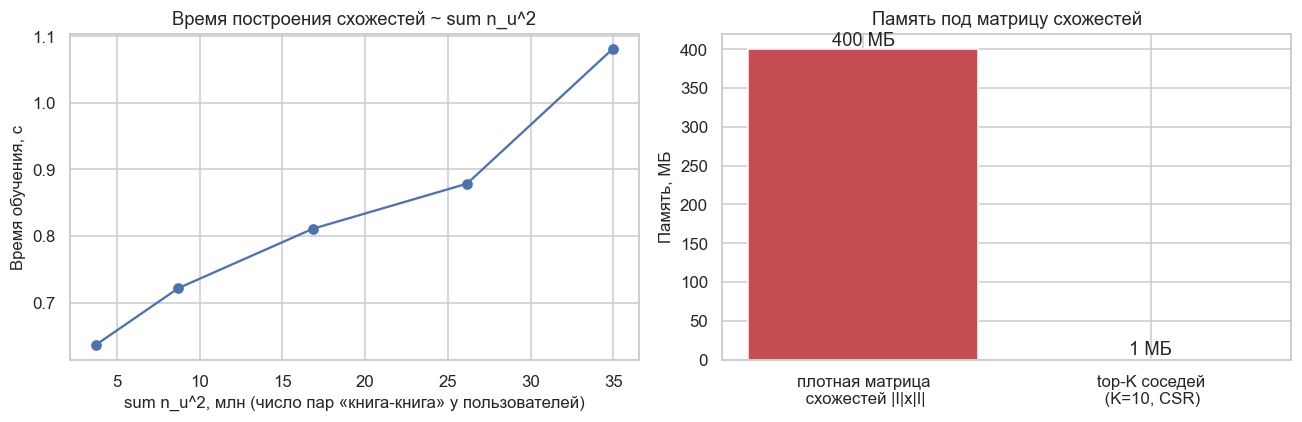

In [23]:
rows = []
for frac in (0.1, 0.25, 0.5, 0.75, 1.0):
    users = np.sort(rng.choice(ds.n_users, int(frac * ds.n_users), replace=False))
    sub = R_trainval[users]
    n_u = sub.getnnz(axis=1)
    t0 = time.time()
    model = ItemBasedCF(feedback="implicit", **CF_PARAMS).fit(sub)
    rows.append({"доля пользователей": frac, "пользователей": len(users), "оценок": sub.nnz,
                 "sum n_u^2": int((n_u.astype(np.int64) ** 2).sum()), "время fit, с": time.time() - t0,
                 "nnz(S)": model.S_.nnz})
scale = pd.DataFrame(rows)
display(scale)

dense_sim_mb = ds.n_items ** 2 * 4 / 1e6
S_mb = (cf_final.S_.data.nbytes + cf_final.S_.indices.nbytes + cf_final.S_.indptr.nbytes) / 1e6
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(scale["sum n_u^2"] / 1e6, scale["время fit, с"], "o-")
ax[0].set(xlabel="sum n_u^2, млн (число пар «книга-книга» у пользователей)", ylabel="Время обучения, с",
          title="Время построения схожестей ~ sum n_u^2")
ax[1].bar(["плотная матрица\n схожестей |I|x|I|", f"top-K соседей\n (K={CF_PARAMS['k']}, CSR)"], [dense_sim_mb, S_mb], color=["C3", "C2"])
ax[1].set(ylabel="Память, МБ", title="Память под матрицу схожестей")
for x_, v in zip((0, 1), (dense_sim_mb, S_mb)):
    ax[1].text(x_, v, f"{v:.0f} МБ", ha="center", va="bottom")
plt.tight_layout(); plt.show()

# Этап 4. Матричные разложения

## 4.1 SVD из библиотеки `surprise`

Модель Саймона Фанка (класс `SVD` в `surprise`): $\hat r_{ui} = \mu + b_u + b_i + p_u^\top q_i$. Параметры обучаются SGD с L2-регуляризацией только на наблюдаемых оценках. Разбиение то же, что и везде (train/val/test по пользователям), метрика - RMSE. Гиперпараметры подбираем на val.

In [24]:
class SVDRecommender(Recommender):
    """Обёртка над surprise.SVD: r_hat(u, i) = mu + b_u + b_i + p_u * q_i.

    После обучения факторы переносятся в numpy-массивы с нашей нумерацией (u, i),
    поэтому оценки для всех книг считаются одним матричным произведением,
    а не циклом по algo.predict.
    """

    name = "SVD (surprise)"

    def __init__(self, n_factors: int = 100, n_epochs: int = 20, lr_all: float = 0.005,
                 reg_all: float = 0.02, random_state: int = 42):
        self.params = dict(n_factors=n_factors, n_epochs=n_epochs, lr_all=lr_all,
                           reg_all=reg_all, random_state=random_state)

    def fit(self, train_df: pd.DataFrame, shape: tuple[int, int]) -> "SVDRecommender":
        """train_df - таблица с колонками u, i, rating; shape - (число пользователей, число книг)."""
        reader = Reader(rating_scale=(1, 5))
        trainset = SurpriseDataset.load_from_df(train_df[["u", "i", "rating"]], reader).build_full_trainset()
        algo = SVD(**self.params)
        algo.fit(trainset)
        self.algo, self.trainset = algo, trainset

        n_users, n_items = shape
        f = self.params["n_factors"]
        self.mu = trainset.global_mean
        self.bu, self.bi = np.zeros(n_users), np.zeros(n_items)
        self.P, self.Q = np.zeros((n_users, f), dtype=np.float32), np.zeros((n_items, f), dtype=np.float32)
        raw_u = np.array([trainset.to_raw_uid(k) for k in range(trainset.n_users)])
        raw_i = np.array([trainset.to_raw_iid(k) for k in range(trainset.n_items)])
        self.bu[raw_u], self.P[raw_u] = algo.bu, algo.pu
        self.bi[raw_i], self.Q[raw_i] = algo.bi, algo.qi            # книги вне train остаются с нулями, как в surprise
        return self

    def predict_ratings(self, users: np.ndarray, items: np.ndarray) -> np.ndarray:
        """Предсказанные оценки для пар (u, i), обрезанные до [1, 5]."""
        raw = self.mu + self.bu[users] + self.bi[items] + np.einsum("nf,nf->n", self.P[users], self.Q[items])
        return np.clip(raw, 1, 5)

    def score(self, users: np.ndarray) -> np.ndarray:
        """Предсказанные оценки всех книг (без обрезания, иначе много одинаковых 5.0)."""
        return (self.mu + self.bu[users, None] + self.bi[None, :] + self.P[users] @ self.Q.T).astype(np.float32)

In [25]:
rows = []
for f, reg in itertools.product((20, 50, 100), (0.05, 0.1, 0.2, 0.4)):
    svd = SVDRecommender(n_factors=f, n_epochs=30, reg_all=reg, random_state=SEED).fit(train_df, ds.shape)
    pred = svd.predict_ratings(val_df["u"].to_numpy(), val_df["i"].to_numpy())
    rows.append({"n_factors": f, "reg_all": reg, "RMSE val": rmse(pred, val_df["rating"])})
svd_grid = pd.DataFrame(rows)
display(svd_grid.pivot(index="n_factors", columns="reg_all", values="RMSE val"))
best = svd_grid.sort_values("RMSE val").iloc[0]
SVD_PARAMS = dict(n_factors=int(best["n_factors"]), n_epochs=30, reg_all=float(best["reg_all"]), random_state=SEED)
print("Выбрано:", SVD_PARAMS)

reg_all,0.0500,0.1000,0.2000,0.4000
n_factors,,,,
20,0.8455,0.8448,0.8463,0.8520
50,0.8468,0.8450,0.8464,0.8521
100,0.8485,0.8454,0.8465,0.8522


Выбрано: {'n_factors': 20, 'n_epochs': 30, 'reg_all': 0.1, 'random_state': 42}


In [26]:
svd_final = SVDRecommender(**SVD_PARAMS).fit(trainval_df, ds.shape)

# проверка: векторизованное предсказание совпадает с algo.predict из surprise
sample = test_df.sample(2000, random_state=SEED)
ours = svd_final.predict_ratings(sample["u"].to_numpy(), sample["i"].to_numpy())
theirs = np.array([svd_final.algo.predict(u, i).est for u, i in zip(sample["u"], sample["i"])])
print(f"max |ours - surprise| = {np.abs(ours - theirs).max():.2e}")

# сравнение по RMSE на test
u_te, i_te, y_te = test_df["u"].to_numpy(), test_df["i"].to_numpy(), test_df["rating"].to_numpy()
global_mean = trainval_df["rating"].mean()
user_mean_tv = trainval_df.groupby("u")["rating"].mean().reindex(range(ds.n_users)).fillna(global_mean).to_numpy()
item_dev = (trainval_df["rating"] - user_mean_tv[trainval_df["u"]]).groupby(trainval_df["i"]).mean() \
    .reindex(range(ds.n_items)).fillna(0).to_numpy()
rmse_tbl = pd.Series({
    "Глобальное среднее": rmse(np.full(len(y_te), global_mean), y_te),
    "Среднее пользователя": rmse(user_mean_tv[u_te], y_te),
    "Среднее пользователя + смещение книги": rmse(np.clip(user_mean_tv[u_te] + item_dev[i_te], 1, 5), y_te),
    "Item-based CF (explicit)": rmse(pred_test_cf, y_te),
    "SVD (surprise)": rmse(svd_final.predict_ratings(u_te, i_te), y_te),
}, name="RMSE на test").to_frame()
display(rmse_tbl)

max |ours - surprise| = 1.81e-08


,RMSE на test
Глобальное среднее,0.9849
Среднее пользователя,0.8913
Среднее пользователя + смещение книги,0.8610
Item-based CF (explicit),0.8211
SVD (surprise),0.8363


Обе коллаборативные модели заметно лучше бейзлайнов: SVD учит смещения и низкоранговые факторы сразу на всех оценках, а item-based CF уточняет базовую оценку по близким книгам, которые пользователь уже оценил. Item-based CF с демпфированием здесь оказался даже немного точнее SVD (0.821 против 0.836 на test); SVD подбирался только по сетке `n_factors x reg_all`, возможно, настройка lr и числа эпох сократила бы разрыв. При этом по RMSE нельзя судить о качестве самих рекомендаций, это покажет этап 5.

## 4.2 `get_recommendations(user_id, N=5)`

Для пользователя предсказываем оценки всех ещё не оценённых книг (одним матричным произведением) и возвращаем N книг с наибольшей предсказанной оценкой.

In [27]:
def get_recommendations(user_id: int, N: int = 5) -> pd.DataFrame:
    # Top-N непрочитанных книг с наибольшей предсказанной оценкой по SVD
    u = ds.user_index(user_id)
    rec = svd_final.recommend(np.array([u]), N, seen=R_trainval)[0]
    out = ds.books.loc[rec, ["book_id", "title", "authors"]].copy()
    out["predicted_rating"] = svd_final.predict_ratings(np.full(N, u), rec)
    out["n_ratings_in_train"] = R_trainval.getnnz(axis=0)[rec]
    return out.reset_index(drop=True)

demo_u = int(np.flatnonzero(R_trainval.getnnz(axis=1) >= 30)[3])
demo_user_id = int(ds.user_ids[demo_u])
hist = trainval_df[(trainval_df.u == demo_u) & (trainval_df.rating == 5)]
display(Markdown(f"**Пользователь {demo_user_id}** - любимые книги (оценка 5), первые 8:"))
display(ds.books.loc[hist["i"].head(8), ["title", "authors"]].reset_index(drop=True))
display(Markdown("**get_recommendations(user_id, N=5):**"))
display(get_recommendations(demo_user_id, N=5))

**Пользователь 41** - любимые книги (оценка 5), первые 8:

,title,authors
0,"Prodigy (Legend, #2)",Marie Lu
1,"Cress (The Lunar Chronicles, #3)",Marissa Meyer
2,"Tempted (House of Night, #6)","P.C. Cast, Kristin Cast"
3,"Lover Awakened (Black Dagger Brotherhood, #3)",J.R. Ward
4,"The Throne of Fire (Kane Chronicles, #2)",Rick Riordan
5,"Linger (The Wolves of Mercy Falls, #2)",Maggie Stiefvater
6,"Champion (Legend, #3)",Marie Lu
7,"Reached (Matched, #3)",Ally Condie


**get_recommendations(user_id, N=5):**

,book_id,title,authors,predicted_rating,n_ratings_in_train
0,5207,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson,5.0000,77
1,6920,The Indispensable Calvin and Hobbes,Bill Watterson,5.0000,78
2,9566,Attack of the Deranged Mutant Killer Monster S...,Bill Watterson,5.0000,87
3,862,"Words of Radiance (The Stormlight Archive, #2)",Brandon Sanderson,5.0000,76
4,6590,The Authoritative Calvin and Hobbes: A Calvin ...,Bill Watterson,5.0000,83


Обратите внимание на `predicted_rating`: SVD предсказывает около 5.0 для книг, которые вообще получают высокие оценки (большой `b_i`), а не для тех, что подходят именно этому читателю. Как это отражается на качестве top-N, посмотрим на этапе 5.

## 4.3 Дополнительно: PureSVD для top-N

SVD из `surprise` оптимизирует точность предсказания значения оценки на известных парах. Для top-N важнее угадать, какие книги пользователь прочтёт и полюбит. Для этого есть PureSVD (Cremonesi et al., 2010): усечённое сингулярное разложение (`scipy.sparse.linalg.svds`) всей неявной матрицы «лайков», где всё ненаблюдаемое считается нулём. Скор пользователя - проекция его вектора на пространство f главных компонент: $x_u V V^\top$. Число факторов f подбираем на val.

In [28]:
class PureSVDRecommender(Recommender):
    """Усечённое SVD бинарной матрицы лайков X ~ U S V^T, ненаблюдаемые ячейки считаются нулями.

    Скор пользователя - проекция его вектора на f главных компонент: x_u V V^T.
    feedback="like": 1, если оценка >= порога; "rated": 1, если оценка вообще есть.
    """

    def __init__(self, n_factors: int = 50, feedback: str = "like",
                 like_threshold: float = LIKE_THRESHOLD, random_state: int = 42):
        assert feedback in {"like", "rated"}
        self.n_factors, self.feedback = n_factors, feedback
        self.like_threshold, self.random_state = like_threshold, random_state
        self.name = f"PureSVD ({feedback}, f={n_factors})"

    def fit(self, train: sparse.csr_matrix) -> "PureSVDRecommender":
        thr = self.like_threshold if self.feedback == "like" else 1
        self.x_ = (train >= thr).astype(np.float32).tocsr()
        rng = np.random.default_rng(self.random_state)
        _, s, vt = svds(self.x_, k=self.n_factors, v0=rng.random(min(self.x_.shape)))
        order = np.argsort(-s)
        self.V_ = np.ascontiguousarray(vt[order].T, dtype=np.float32)   # книги x факторы
        return self

    def score(self, users: np.ndarray) -> np.ndarray:
        return (self.x_[users] @ self.V_) @ self.V_.T

,n_factors,nDCG@10,R@10,"время fit, с"
0,50,0.0249,0.0349,5.6544
1,100,0.0468,0.0685,7.3843
2,200,0.0739,0.1089,11.3166
3,300,0.0903,0.1332,14.4592
4,500,0.1130,0.1681,26.4951
5,800,0.1319,0.1948,46.6963


Выбрано: {'n_factors': 800}


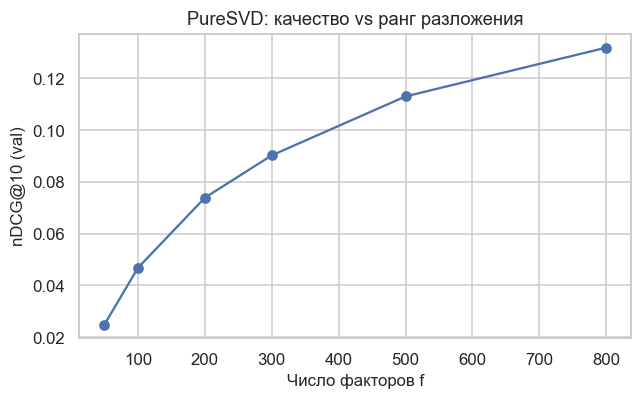

In [29]:
rows = []
for f in (50, 100, 200, 300, 500, 800):
    t0 = time.time()
    m = PureSVDRecommender(n_factors=f).fit(R_train)
    res = evaluate_ranking(m, R_train, val_df, ks=(K_MAIN,))
    rows.append({"n_factors": f, "nDCG@10": res.summary["nDCG@10"], "R@10": res.summary["R@10"], "время fit, с": time.time() - t0})
pure_grid = pd.DataFrame(rows)
display(pure_grid)
PURE_PARAMS = dict(n_factors=int(pure_grid.sort_values("nDCG@10", ascending=False).iloc[0]["n_factors"]))
print("Выбрано:", PURE_PARAMS)

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(pure_grid["n_factors"], pure_grid["nDCG@10"], "o-")
ax.set(xlabel="Число факторов f", ylabel="nDCG@10 (val)", title="PureSVD: качество vs ранг разложения")
plt.tight_layout(); plt.show()

# Этап 5. Оценка и сравнение моделей

Финальные модели обучены на trainval, оценка идёт на test, который не участвовал ни в обучении, ни в подборе гиперпараметров. Для каждого пользователя берём top-K среди книг, которых нет в его trainval; релевантными считаем книги с оценкой >= 4 в test.

Метрики (функции определены выше, там же есть проверка на ручных примерах):
- Precision@K = (число релевантных в top-K) / K
- Recall@K = (число релевантных в top-K) / (число релевантных у пользователя в test)
- nDCG@K = DCG@K / IDCG@K, где $\mathrm{DCG@K} = \sum_{r=1}^{K} \dfrac{\mathrm{rel}_r}{\log_2(r+1)}$ учитывает позицию релевантных книг, а IDCG - DCG идеальной выдачи.

Дополнительно считаем coverage@K (доля каталога, попавшая хоть в чью-то выдачу) и avg_pop@K (среднее число train-оценок у рекомендованных книг), чтобы видеть смещение популярности.

Функция `build_models` обучает все модели с выбранными гиперпараметрами на заданной выборке. Её используем и для финальных моделей (на trainval), и дальше для гибрида и эксперимента с новыми книгами.

In [30]:
def build_models(train_df: pd.DataFrame, ds: Dataset, params: dict) -> dict:
    """Обучает все модели на train_df (колонки u, i, rating)."""
    train = to_csr(train_df, ds.shape)
    return {
        "random": RandomRecommender().fit(train),
        "pop": PopularityRecommender(**params["popularity"]).fit(train),
        "content": ContentBasedRecommender().fit_items(ds.books, ds.book_tags).fit(train),
        "cf": ItemBasedCF(feedback="implicit", **params["item_cf"]).fit(train),
        "cf_explicit": ItemBasedCF(feedback="explicit", **params["item_cf_explicit"]).fit(train),
        "svd": SVDRecommender(**params["svd"]).fit(train_df, ds.shape),
        "pure": PureSVDRecommender(**params["pure_svd"]).fit(train),
    }

In [31]:
PARAMS = {
    "popularity": POP_PARAMS,
    "item_cf": CF_PARAMS,
    "item_cf_explicit": CF_EXPLICIT_PARAMS,
    "svd": SVD_PARAMS,
    "pure_svd": PURE_PARAMS,
}
final = build_models(trainval_df, ds, PARAMS)          # всё обучено на trainval

MODEL_NAMES = {
    "random": "Random (reference)",
    "pop": "Popularity (mean rating)",
    "content": "Content-based (TF-IDF)",
    "cf": "Item-based CF (implicit)",
    "cf_explicit": "Item-based CF (explicit)",
    "svd": "SVD (surprise)",
    "pure": "PureSVD (implicit)",
}
results = {MODEL_NAMES[k]: evaluate_ranking(final[k], R_trainval, test_df, ks=KS) for k in MODEL_NAMES}
print("Пользователей в оценке:", int(next(iter(results.values())).summary["n_users"]))

Пользователей в оценке: 43434


In [32]:
main_cols = ["P@10", "R@10", "nDCG@10", "coverage@10", "avg_pop@10"]
summary_tbl = results_table(results, columns=main_cols)
display(Markdown("### Сводная таблица (test, K = 10)"))
display(summary_tbl.style.format("{:.4f}").background_gradient(axis=0, subset=["P@10", "R@10", "nDCG@10"], cmap="Greens"))

full_tbl = pd.concat({m: pd.DataFrame({name: r.summary for name, r in results.items()}).T[[f"{m}@{k}" for k in KS]]
                      .set_axis([f"K={k}" for k in KS], axis=1) for m in ("P", "R", "nDCG")}, axis=1)
display(Markdown("### Все метрики при K = 5, 10, 20"))
display(full_tbl)

### Сводная таблица (test, K = 10)

,P@10,R@10,nDCG@10,coverage@10,avg_pop@10
Random (reference),0.0004,0.0011,0.0007,0.8691,77.5914
Popularity (mean rating),0.0005,0.0016,0.0011,0.0019,77.8053
Content-based (TF-IDF),0.0422,0.1645,0.1254,0.9434,77.6207
Item-based CF (implicit),0.0752,0.2510,0.2110,0.9830,76.8429
Item-based CF (explicit),0.0492,0.1355,0.1241,0.9889,78.3746
SVD (surprise),0.0005,0.0014,0.0009,0.0036,77.8736
PureSVD (implicit),0.0713,0.2105,0.1747,0.8347,78.6943


### Все метрики при K = 5, 10, 20

P                    R                 nDCG              
                            K=5   K=10   K=20    K=5   K=10   K=20    K=5   K=10   K=20
Random (reference)       0.0003 0.0004 0.0004 0.0004 0.0011 0.0021 0.0004 0.0007 0.0010
Popularity (mean rating) 0.0005 0.0005 0.0005 0.0009 0.0016 0.0032 0.0009 0.0011 0.0016
Content-based (TF-IDF)   0.0588 0.0422 0.0289 0.1232 0.1645 0.2137 0.1133 0.1254 0.1403
Item-based CF (implicit) 0.1084 0.0752 0.0495 0.1963 0.2510 0.3051 0.1988 0.2110 0.2273
Item-based CF (explicit) 0.0729 0.0492 0.0316 0.1069 0.1355 0.1652 0.1205 0.1241 0.1324
SVD (surprise)           0.0005 0.0005 0.0005 0.0007 0.0014 0.0031 0.0007 0.0009 0.0014
PureSVD (implicit)       0.1002 0.0713 0.0478 0.1552 0.2105 0.2751 0.1630 0.1747 0.1933

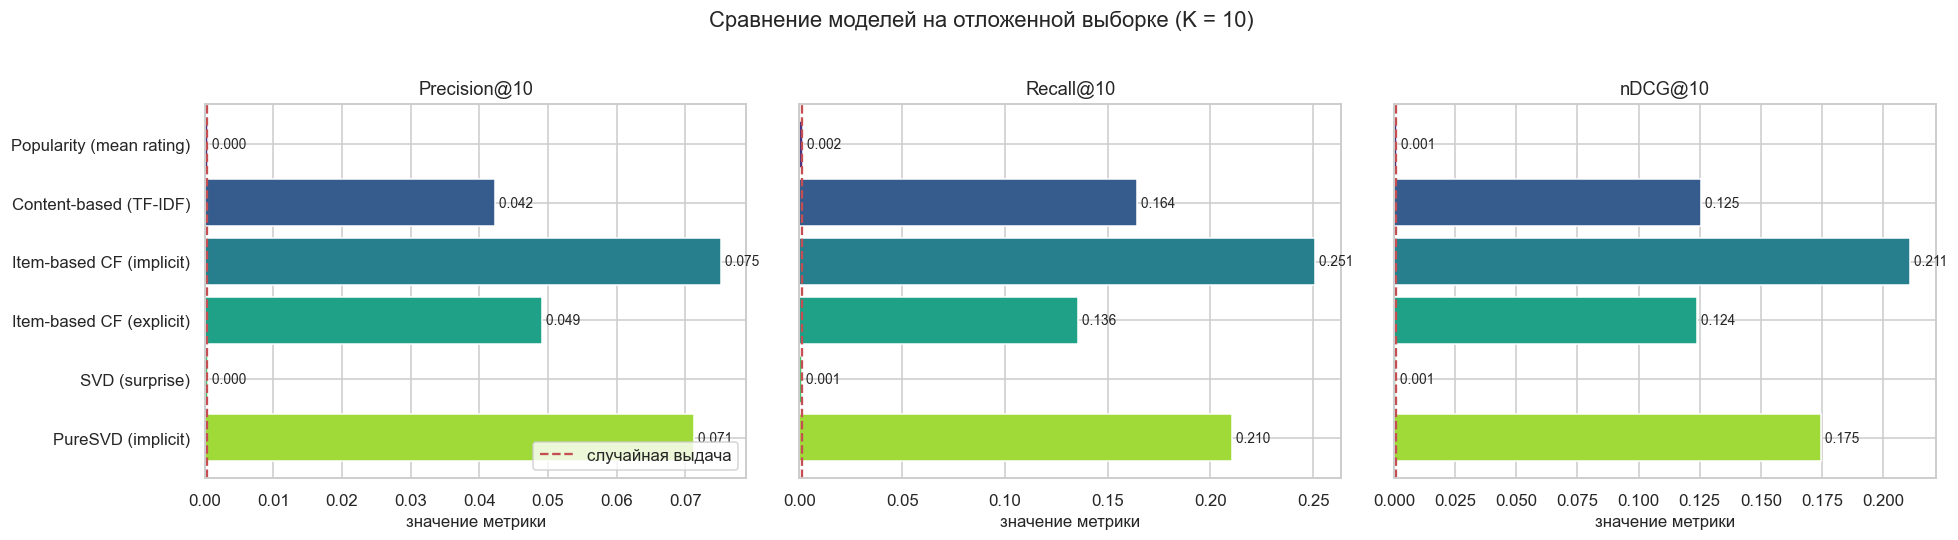

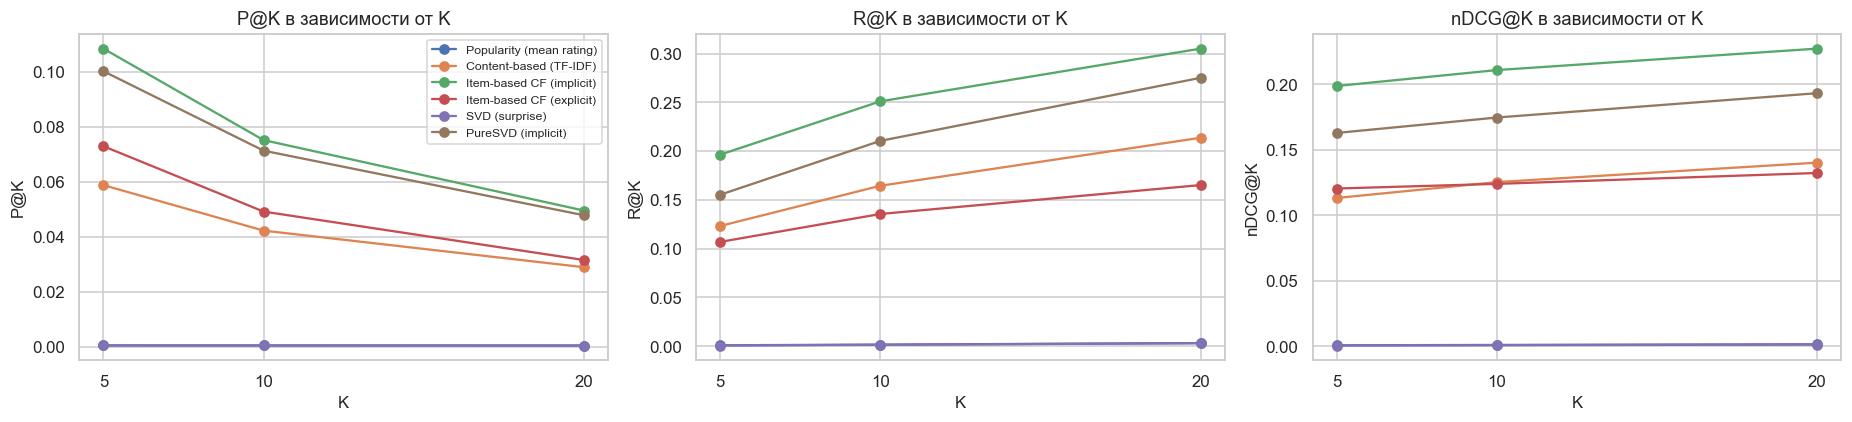

In [33]:
plot_models = [m for m in results if not m.startswith("Random")]
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8), sharey=False)
for a, metric, title in zip(ax, ("P", "R", "nDCG"), ("Precision@10", "Recall@10", "nDCG@10")):
    vals = [results[m].summary[f"{metric}@10"] for m in plot_models]
    bars = a.barh(plot_models, vals, color=sns.color_palette("viridis", len(plot_models)))
    a.axvline(results["Random (reference)"].summary[f"{metric}@10"], color="r", ls="--", label="случайная выдача")
    for b, v in zip(bars, vals):
        a.text(v, b.get_y() + b.get_height() / 2, f" {v:.3f}", va="center", fontsize=9)
    a.set(title=title, xlabel="значение метрики"); a.invert_yaxis()
    if metric != "P": a.set_yticklabels([])
ax[0].legend(loc="lower right")
plt.suptitle("Сравнение моделей на отложенной выборке (K = 10)", y=1.02)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, metric in zip(ax, ("P", "R", "nDCG")):
    for m in plot_models:
        a.plot(KS, [results[m].summary[f"{metric}@{k}"] for k in KS], "o-", label=m)
    a.set(xlabel="K", ylabel=f"{metric}@K", title=f"{metric}@K в зависимости от K", xticks=KS)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Качество по группам активности пользователей

Холодный старт для пользователей: как качество моделей зависит от числа оценок пользователя в train?

,пользователей,Popularity (mean rating),Content-based (TF-IDF),Item-based CF (implicit),SVD (surprise),PureSVD (implicit)
n_train,,,,,,
1-3,12067,0.0011,0.1146,0.1577,0.0004,0.0831
4-6,6925,0.0008,0.1333,0.1976,0.0006,0.1428
7-12,7301,0.0008,0.1286,0.2099,0.0008,0.1770
13-25,8219,0.0013,0.1264,0.2306,0.0012,0.2151
26-50,5665,0.0018,0.1282,0.2550,0.0015,0.2599
51+,3257,0.0012,0.1350,0.3131,0.0022,0.3273


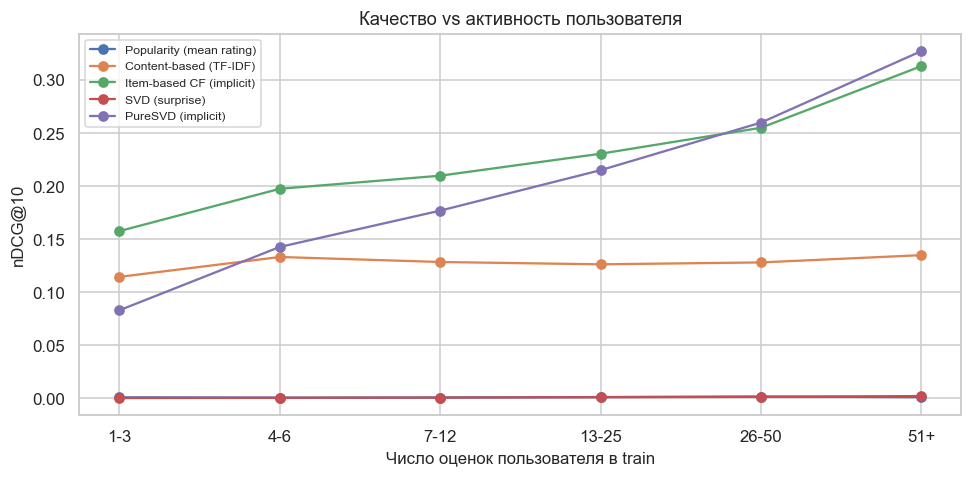

In [34]:
act_bins = [0, 3, 6, 12, 25, 50, 10**6]
act_labels = ["1-3", "4-6", "7-12", "13-25", "26-50", "51+"]

def by_activity(res_dict, metric="nDCG@10", names=None):
    cols = {}
    for name in names or res_dict:
        pu = res_dict[name].per_user
        cols[name] = pu.groupby(pd.cut(pu["n_train"], act_bins, labels=act_labels))[metric].mean()
    return pd.DataFrame(cols)

act_models = [m for m in results if m not in ("Random (reference)", "Item-based CF (explicit)")]
act_tbl = by_activity(results, names=act_models)
act_tbl.insert(0, "пользователей", results["Popularity (mean rating)"].per_user.groupby(
    pd.cut(results["Popularity (mean rating)"].per_user["n_train"], act_bins, labels=act_labels)).size())
display(act_tbl)

fig, ax = plt.subplots(figsize=(9, 4.5))
for m in act_models:
    ax.plot(act_labels, act_tbl[m].values, "o-", label=m)
ax.set(xlabel="Число оценок пользователя в train", ylabel="nDCG@10", title="Качество vs активность пользователя")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Откуда берётся сигнал: серии и авторы

Коллаборативные и контентные модели на порядки превосходят случайную выдачу. Проверим одну из причин: насколько часто понравившаяся в test книга
имеет **того же автора** или **ту же серию**, что книга, которая уже понравилась пользователю в train.

In [35]:
first_author = ds.books["authors"].str.split(",").str[0].str.strip()
series = ds.books["title"].str.extract(r"\(([^()]*?),?\s*#\d+[^()]*\)")[0]
series = series.where(series.notna(), "__none__" + ds.books.index.astype(str))        # у книг без серии - уникальный ключ

def share_related(keys):
    codes = pd.factorize(keys)[0]
    item_key = sparse.csr_matrix((np.ones(ds.n_items), (np.arange(ds.n_items), codes)))      # книга -> автор/серия
    user_key = (R_trainval >= LIKE_THRESHOLD).astype(np.float32) @ item_key                     # пользователь -> автор/серия
    t = test_df[test_df["rating"] >= LIKE_THRESHOLD]
    real = np.asarray(user_key[t["u"].to_numpy(), codes[t["i"].to_numpy()]]).ravel() > 0
    rand_items = rng.integers(0, ds.n_items, len(t))
    rand = np.asarray(user_key[t["u"].to_numpy(), codes[rand_items]]).ravel() > 0
    return real.mean(), rand.mean()

rel_tbl = pd.DataFrame({k: share_related(v) for k, v in {"тот же автор": first_author, "та же серия": series}.items()},
                       index=["понравившиеся книги из test", "случайные книги (для сравнения)"]).T
display(rel_tbl.style.format("{:.1%}"))

item_pop_tv = np.asarray(R_trainval.getnnz(axis=0)).ravel()
t_rel = test_df[test_df["rating"] >= LIKE_THRESHOLD]
print(f"Популярность (число оценок в trainval): у понравившихся в test книг в среднем {item_pop_tv[t_rel['i']].mean():.1f}, "
      f"у случайной книги каталога {item_pop_tv.mean():.1f} - популярность в этой выборке почти не предсказывает выбор пользователя.")

,понравившиеся книги из test,случайные книги (для сравнения)
тот же автор,39.0%,1.5%
та же серия,23.0%,0.6%


Популярность (число оценок в trainval): у понравившихся в test книг в среднем 76.8, у случайной книги каталога 77.6 - популярность в этой выборке почти не предсказывает выбор пользователя.


## Анализ результатов этапа 5

По nDCG@10 на test модели выстраиваются так: Item-based CF (implicit) 0.211, PureSVD 0.175, Content-based 0.125, Item-based CF (explicit) 0.124, а Popularity и SVD из surprise (около 0.001) на уровне случайной выдачи (0.0007). Порядок по Precision и Recall такой же при всех K.

Popularity. В `ratings.csv` у каждой книги не больше 100 оценок, поэтому популярность внутри выборки ничего не говорит о выборе пользователя: средняя популярность понравившихся в test книг (76.8) почти равна средней по каталогу (77.6). Кроме того, топ по среднему рейтингу один для всех (сборники Calvin and Hobbes, боксы Harry Potter), coverage@10 всего 0.2%.

SVD из surprise. При хорошем RMSE ранжирует на уровне случайного. Он учится предсказывать значение оценки на парах, которые пользователь уже оценил, и не знает, какие книги тот вообще читает. Сортировка по предсказанной оценке поднимает книги с большим смещением `b_i` (опять сборники комиксов для всех, coverage@10 = 0.4%), а персональная часть `p_u*q_i` почти не влияет на порядок. Получается, что низкий RMSE не гарантирует хороший top-N.

Item-CF по лайкам и PureSVD. Они моделируют то, что нужно для top-N: какие книги читают и любят вместе. В этих данных сигнал локальный: у 39% понравившихся в test книг тот же первый автор, что у понравившейся пользователю книги из train (у случайной книги 1.5%), у 23% - та же серия (0.6%). Item-CF с K=10 соседями ловит это напрямую (соседние тома серии), поэтому лучшее K маленькое. PureSVD должен выделить фактор под каждую серию или автора, поэтому его качество растёт до 800 факторов и приближается к Item-CF, а при 50 факторах он почти бесполезен.

Контентная модель (название и теги, без оценок других пользователей) в сотню с лишним раз лучше случайной, но почти вдвое хуже CF: она видит сходство текстов, но не вкусы читателей. Зато её качество не зависит ни от активности пользователя, ни от числа оценок книги.

Item-CF (explicit) как ранкер хуже implicit-версии: центрированные оценки смешивают «понравилось» и «не понравилось», а книги с одним-двумя близкими соседями получают завышенный скор.

Активность пользователей. У коллаборативных моделей качество растёт с числом оценок (Item-CF: 0.16 -> 0.31). PureSVD хуже всех у новичков (1-3 оценки: 0.08), а у самых активных (51+) чуть лучше Item-CF. Контентная модель почти не зависит от активности (0.115-0.135). Даже при 1-3 оценках Item-CF остаётся лучше контента, но разрыв там самый маленький, а у пользователя совсем без истории не сработает ни одна персональная модель.

Ограничение протокола. Оценка офлайн и случайная: проверяем, угадает ли модель книги, которые пользователь в итоге прочитал и оценил. Заметная часть из них - продолжение серии или автора, поэтому абсолютные значения метрик выше, чем были бы в задаче «показать что-то новое». Для реальной системы нужны A/B-тест и метрики разнообразия и новизны.

# Этап 6. Гибридизация и выводы

## 6.1 Гибридный подход

Коллаборативные модели (Item-CF, SVD, PureSVD) лучше всего угадывают вкусы там, где достаточно оценок, контентная модель работает и для книг без оценок, а популярное годится как запасной вариант. Объединяем их так:

$$
\text{score}(u,i) \;=\; c_i \cdot \sum_{m} w_m\, z_m(u,i) \;+\; (1 - c_i)\cdot z_{\text{content}}(u,i), \qquad c_i = \frac{n_i}{n_i + c}
$$

- $z_m$ - скор модели m (Popularity, SVD, PureSVD, Item-CF, Content), стандартизованный по каждому пользователю (z-score), чтобы можно было складывать скоры с разными шкалами;
- $w_m$ - веса моделей (сумма равна 1), подбираются перебором по сетке на val;
- $c_i = n_i/(n_i+c)$ - доверие к коллаборативным сигналам для книги i, где $n_i$ - число её оценок в train, а $c=3$. У холодной книги $c_i \to 0$, и её ранжирует только контентная модель; у популярной $c_i \to 1$, и работает вся смесь.

Это реализует идею из задания (для новых книг контент, для известных коллаборативные модели), но плавно и без жёсткого порога: у книг с 2-3 оценками коллаборативному сигналу доверять нельзя. Для пользователей с малым числом оценок смотрите анализ по активности выше.

In [36]:
def blend(z: dict[str, np.ndarray], weights: dict[str, float], conf: np.ndarray,
          content_key: str = "content") -> np.ndarray:
    """score = conf_i * sum_m w_m * z_m + (1 - conf_i) * z_content (z - стандартизованные скоры)."""
    mix = sum(w * z[k] for k, w in weights.items() if w > 0)
    return conf[None, :] * mix + (1 - conf[None, :]) * z[content_key]


class HybridRecommender(Recommender):
    """Гибрид: conf_i = n_i / (n_i + c), где n_i - число оценок книги i в train."""

    name = "Hybrid"

    def __init__(self, models: dict[str, Recommender], weights: dict[str, float],
                 item_counts: np.ndarray, content_key: str = "content", c: float = 5.0):
        self.models, self.weights, self.content_key = models, weights, content_key
        self.conf = (item_counts / (item_counts + c)).astype(np.float32)

    def score(self, users: np.ndarray) -> np.ndarray:
        z = {k: zscore(m.score(users)) for k, m in self.models.items()
             if self.weights.get(k, 0) > 0 or k == self.content_key}
        return blend(z, self.weights, self.conf, self.content_key)


class PrecomputedScores(Recommender):
    """Отдаёт заранее посчитанную матрицу скоров (для быстрого перебора весов)."""

    def __init__(self, scores: np.ndarray):
        self.scores = scores

    def score(self, users: np.ndarray) -> np.ndarray:
        assert len(users) == len(self.scores)
        return self.scores


def tune_weights(z: dict[str, np.ndarray], conf: np.ndarray, users: np.ndarray, train: sparse.csr_matrix,
                 val_df: pd.DataFrame, step: float = 0.1, metric: str = "nDCG@10",
                 content_key: str = "content") -> tuple[dict[str, float], pd.DataFrame]:
    """Перебор весов с шагом step (сумма весов равна 1), оценка на val_df.

    z - стандартизованные скоры моделей для users (строки соответствуют users).
    Возвращает лучшие веса и таблицу всех комбинаций.
    """
    names = list(z)
    n = int(round(1 / step))
    rows = []
    for combo in itertools.product(range(n + 1), repeat=len(names) - 1):
        if sum(combo) > n:
            continue
        w = dict(zip(names, [c * step for c in combo] + [(n - sum(combo)) * step]))
        scores = blend(z, w, conf, content_key)
        res = evaluate_ranking(PrecomputedScores(scores), train, val_df, ks=(10,), users=users,
                               batch_size=len(users))
        rows.append({**w, metric: res.summary[metric], "R@10": res.summary["R@10"]})
    table = pd.DataFrame(rows).sort_values(metric, ascending=False).reset_index(drop=True)
    best = {k: float(table.loc[0, k]) for k in names}
    return best, table

In [37]:
# --- 1. модели, обученные на train; скоры для выборки пользователей val
COMPONENTS = ["pop", "svd", "pure", "cf", "content"]
models_val = build_models(train_df, ds, PARAMS)

rel_users = np.unique(val_df.loc[val_df["rating"] >= LIKE_THRESHOLD, "u"])
tune_users = np.sort(rng.choice(rel_users, 2000, replace=False))     # отсортированы и имеют релевантные книги
z_val = {k: zscore(models_val[k].score(tune_users)) for k in COMPONENTS}

C_CONF = 3.0
counts_train = np.asarray(R_train.getnnz(axis=0)).ravel()
conf_train = counts_train / (counts_train + C_CONF)

t0 = time.time()
best_w, w_table = tune_weights(z_val, conf_train, tune_users, R_train, val_df, step=0.1, metric="nDCG@10")
print(f"Перебрано {len(w_table)} комбинаций весов за {time.time() - t0:.0f} с")
display(w_table.head(10))
print("Лучшие веса:", best_w)

Перебрано 1001 комбинаций весов за 352 с


,pop,svd,pure,cf,content,nDCG@10,R@10
0,0.0000,0.3000,0.0000,0.4000,0.3000,0.1622,0.2331
1,0.0000,0.1000,0.1000,0.4000,0.4000,0.1621,0.2337
2,0.0000,0.3000,0.0000,0.3000,0.4000,0.1621,0.2319
3,0.0000,0.4000,0.0000,0.4000,0.2000,0.1621,0.2325
4,0.0000,0.5000,0.0000,0.3000,0.2000,0.1620,0.2316
5,0.4000,0.0000,0.0000,0.3000,0.3000,0.1619,0.2325
6,0.0000,0.4000,0.0000,0.3000,0.3000,0.1619,0.2321
7,0.0000,0.1000,0.0000,0.4000,0.5000,0.1617,0.2325
8,0.2000,0.2000,0.0000,0.3000,0.3000,0.1617,0.2311
9,0.0000,0.2000,0.0000,0.4000,0.4000,0.1617,0.2325


Лучшие веса: {'pop': 0.0, 'svd': 0.30000000000000004, 'pure': 0.0, 'cf': 0.4, 'content': 0.30000000000000004}


In [38]:
# сравнение с «одиночными» моделями на той же val-выборке и чувствительность к параметру c
rows = {}
for k in COMPONENTS:
    rows[k] = evaluate_ranking(PrecomputedScores(z_val[k]), R_train, val_df, ks=(10,), users=tune_users, batch_size=len(tune_users)).summary["nDCG@10"]
for c_ in (1, 3, 10, 30):
    cnt = counts_train / (counts_train + c_)
    rows[f"hybrid (c={c_})"] = evaluate_ranking(PrecomputedScores(blend(z_val, best_w, cnt)), R_train, val_df, ks=(10,),
                                                 users=tune_users, batch_size=len(tune_users)).summary["nDCG@10"]
display(pd.Series(rows, name="nDCG@10 (val)").to_frame())

,nDCG@10 (val)
pop,0.0009
svd,0.0005
pure,0.1350
cf,0.1600
content,0.1018
hybrid (c=1),0.1619
hybrid (c=3),0.1622
hybrid (c=10),0.1616
hybrid (c=30),0.1609


In [39]:
# --- 2. финальная гибридная модель: компоненты обучены на trainval, веса подобраны на val
counts_trainval = np.asarray(R_trainval.getnnz(axis=0)).ravel()
hybrid = HybridRecommender({k: final[k] for k in COMPONENTS}, best_w, counts_trainval, c=C_CONF)
results["Hybrid"] = evaluate_ranking(hybrid, R_trainval, test_df, ks=KS)

display(Markdown("### Итоговая сводная таблица на test (K = 10), включая гибрид"))
summary_tbl = results_table(results, columns=main_cols)
display(summary_tbl.style.format("{:.4f}").background_gradient(axis=0, subset=["P@10", "R@10", "nDCG@10"], cmap="Greens"))

### Итоговая сводная таблица на test (K = 10), включая гибрид

,P@10,R@10,nDCG@10,coverage@10,avg_pop@10
Random (reference),0.0004,0.0011,0.0007,0.8691,77.5914
Popularity (mean rating),0.0005,0.0016,0.0011,0.0019,77.8053
Content-based (TF-IDF),0.0422,0.1645,0.1254,0.9434,77.6207
Item-based CF (implicit),0.0752,0.2510,0.2110,0.9830,76.8429
Item-based CF (explicit),0.0492,0.1355,0.1241,0.9889,78.3746
SVD (surprise),0.0005,0.0014,0.0009,0.0036,77.8736
PureSVD (implicit),0.0713,0.2105,0.1747,0.8347,78.6943
Hybrid,0.0757,0.2558,0.2131,0.9895,76.5988


In [40]:
# парное сравнение гибрида с одиночными моделями: разность метрики по пользователям и 95% доверительный интервал
def paired_diff(a, b, metric):
    d = results[a].per_user[metric] - results[b].per_user[metric]
    m, se = d.mean(), d.std() / np.sqrt(len(d))
    return pd.Series({"разность": m, "95% ДИ от": m - 1.96 * se, "95% ДИ до": m + 1.96 * se})

paired = pd.concat({f"{metric}: Hybrid - {b}": paired_diff("Hybrid", b, metric)
                    for metric in ("nDCG@10", "R@10")
                    for b in ("Item-based CF (implicit)", "PureSVD (implicit)", "Content-based (TF-IDF)")}, axis=1).T
display(paired)

,разность,95% ДИ от,95% ДИ до
nDCG@10: Hybrid - Item-based CF (implicit),0.0021,0.0016,0.0025
nDCG@10: Hybrid - PureSVD (implicit),0.0383,0.0365,0.0401
nDCG@10: Hybrid - Content-based (TF-IDF),0.0876,0.0856,0.0896
R@10: Hybrid - Item-based CF (implicit),0.0048,0.0039,0.0057
R@10: Hybrid - PureSVD (implicit),0.0453,0.0429,0.0478
R@10: Hybrid - Content-based (TF-IDF),0.0913,0.0887,0.0939


In [41]:
def show_recs(model, user_id: int, N: int = 5) -> pd.DataFrame:
    u = ds.user_index(user_id)
    rec = model.recommend(np.array([u]), N, seen=R_trainval)[0]
    return ds.books.loc[rec, ["title", "authors"]].reset_index(drop=True)

display(Markdown(f"**Пользователь {demo_user_id}** (читает молодёжное фэнтези/антиутопии, см. выше). Топ-5 разных моделей:"))
for name, model in [("Item-based CF (implicit)", final["cf"]), ("Hybrid", hybrid)]:
    display(Markdown(f"*{name}*"))
    display(show_recs(model, demo_user_id))

**Пользователь 41** (читает молодёжное фэнтези/антиутопии, см. выше). Топ-5 разных моделей:

*Item-based CF (implicit)*

,title,authors
0,"For a Few Demons More (The Hollows, #5)",Kim Harrison
1,"The Never War (Pendragon, #3)",D.J. MacHale
2,"The Reality Bug (Pendragon, #4)",D.J. MacHale
3,"Every Which Way But Dead (The Hollows, #3)",Kim Harrison
4,"Raven Rise (Pendragon, #9)",D.J. MacHale


*Hybrid*

,title,authors
0,"For a Few Demons More (The Hollows, #5)",Kim Harrison
1,"The Never War (Pendragon, #3)",D.J. MacHale
2,"The Reality Bug (Pendragon, #4)",D.J. MacHale
3,"Every Which Way But Dead (The Hollows, #3)",Kim Harrison
4,"A Perfect Blood (The Hollows, #10)",Kim Harrison


## 6.2 Эксперимент «новые книги» (холодный старт книг)

Смоделируем появление новых книг: случайно выбираем 10% каталога (1000 книг) и полностью убираем их оценки из обучения, то есть для моделей это книги без единой оценки. Все модели переобучаем на оставшейся части и просим ранжировать только новые книги. Релевантными считаются новые книги, которые пользователь на самом деле оценил на 4 и выше. Случайная выдача среди 1000 книг служит нижней границей.

Пользователей в оценке: 25889; книг-кандидатов: 1000; число оценок новых книг в обучении: 0

,P@10,R@10,nDCG@10,coverage@10
Random (reference),0.0025,0.0100,0.0058,1.0000
Popularity (mean rating),0.0024,0.0084,0.0051,0.0100
Content-based (TF-IDF),0.0826,0.3395,0.2638,0.9990
Item-based CF (implicit),0.0024,0.0084,0.0051,0.0100
Item-based CF (explicit),0.0024,0.0084,0.0051,0.0100
SVD (surprise),0.0024,0.0084,0.0051,0.0100
PureSVD (implicit),0.0022,0.0090,0.0053,0.4160
Hybrid,0.0826,0.3395,0.2638,0.9990


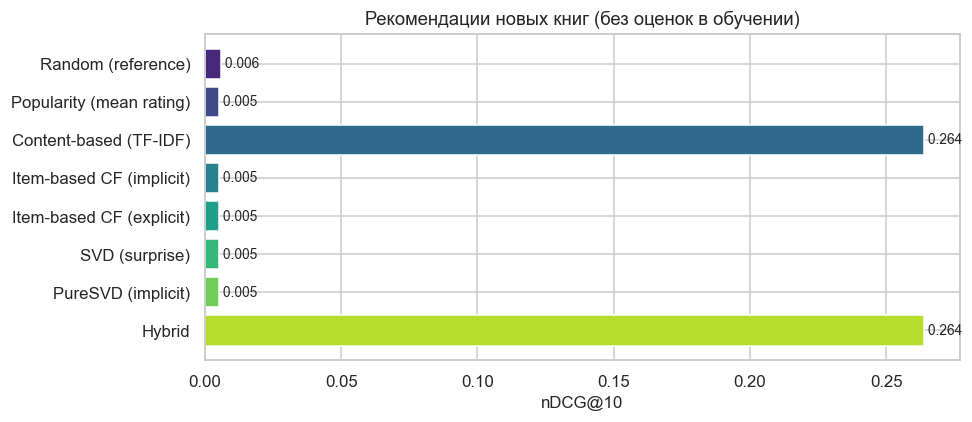

In [42]:
cold_items = np.sort(rng.choice(ds.n_items, 1000, replace=False))
is_cold = np.zeros(ds.n_items, dtype=bool); is_cold[cold_items] = True

warm_df = trainval_df[~is_cold[trainval_df["i"].to_numpy()]]
R_warm = to_csr(warm_df, ds.shape)
cold_ratings = ratings[is_cold[ratings["i"].to_numpy()]]            # все оценки «новых» книг - это «будущее»

models_cold = build_models(warm_df, ds, PARAMS)
counts_warm = np.asarray(R_warm.getnnz(axis=0)).ravel()
hybrid_cold = HybridRecommender({k: models_cold[k] for k in COMPONENTS}, best_w, counts_warm, c=C_CONF)

cold_models = {**{MODEL_NAMES[k]: models_cold[k] for k in MODEL_NAMES}, "Hybrid": hybrid_cold}
results_cold = {name: evaluate_ranking(m, R_warm, cold_ratings, ks=KS, candidates=cold_items)
                for name, m in cold_models.items()}
cold_tbl = results_table(results_cold, columns=["P@10", "R@10", "nDCG@10", "coverage@10"])
display(Markdown(f"Пользователей в оценке: {int(next(iter(results_cold.values())).summary['n_users'])}; "
                 f"книг-кандидатов: {len(cold_items)}; число оценок новых книг в обучении: {int(counts_warm[cold_items].sum())}"))
display(cold_tbl.style.format("{:.4f}").background_gradient(axis=0, subset=["P@10", "R@10", "nDCG@10"], cmap="Greens"))

fig, ax = plt.subplots(figsize=(9, 4))
vals = cold_tbl["nDCG@10"]
bars = ax.barh(vals.index, vals.values, color=sns.color_palette("viridis", len(vals)))
ax.set(xlabel="nDCG@10", title="Рекомендации новых книг (без оценок в обучении)"); ax.invert_yaxis()
for b, v in zip(bars, vals.values):
    ax.text(v, b.get_y() + b.get_height() / 2, f" {v:.3f}", va="center", fontsize=9)
plt.tight_layout(); plt.show()

## Анализ гибрида

На обычной выборке гибрид немного лучше Item-CF: nDCG@10 0.2131 против 0.2110, Recall@10 0.256 против 0.251. Парные 95% доверительные интервалы разности (таблица выше): для nDCG@10 [+0.0016; +0.0025], для Recall@10 [+0.0039; +0.0057]. Прирост значим, но порядка 1%: Item-CF уже ловит почти весь доступный сигнал, остальные модели лишь слегка его поправляют. Оптимум по весам плоский (лучшие 10 комбинаций различаются в четвёртом знаке), поэтому конкретные значения весов не стоит интерпретировать буквально.

Popularity и PureSVD получили нулевые веса, а SVD из surprise - 0.3, хотя сам по себе он не лучше случайного. Его скор - это в основном смещение книги `b_i`, то есть оценка общего качества, и в смеси он работает как поправка на качество к персональным скорам CF и контента. Для демонстрационного пользователя рекомендации CF и гибрида совпадают на 4 позициях из 5.

Новые книги. Здесь разница принципиальная. У коллаборативных моделей и Popularity нет ни одной оценки новых книг, они выдают одинаковые нули, и качество у них на уровне случайной выдачи (nDCG@10 около 0.005 против 0.006 у Random). Контентная модель даёт nDCG@10 0.264 и Recall@10 0.34, то есть в десятки раз больше. В гибриде для таких книг c_i = 0, их ранжирует только контент, поэтому он сохраняет это качество, а для известных книг работает как смесь CF, SVD-поправки и контента. Параметр c мало влияет на качество на обычной выборке (таблица чувствительности выше), поэтому взято c = 3: книги с тремя оценками и меньше считаем «ненадёжными» для коллаборативной части.

Холодные пользователи. Уже при 1-3 оценках CF лучше контента. Для пользователя совсем без оценок нужны неперсональные рекомендации (популярное, подборки редакции) или онбординг: спросить про несколько любимых книг или жанров, после чего заработают контентный профиль и CF. В этом датасете «популярное» не лучше случайного из-за сэмплирования, но в реальной системе без ограничения числа оценок на книгу такой запасной вариант имеет смысл. Гибрид можно развить дальше, сделав веса зависимыми от числа оценок пользователя.

# Итоговые выводы

## 1. Какая модель показала лучшее качество и почему

Лучшая одиночная модель - item-based CF по неявной обратной связи (nDCG@10 0.211, Recall@10 0.251). Гибрид чуть лучше (0.213), а на новых книгах заметно лучше всех за счёт контентной части. Причины:
- для top-N важно угадать, что пользователь прочтёт и полюбит, а не какую оценку он поставит; item-CF и PureSVD работают с бинарной матрицей лайков как раз для этого;
- сигнал в данных локальный (авторы и серии), и его напрямую ловит небольшое число ближайших соседей;
- SVD из surprise и Popularity ранжируют по общему качеству книги и не персонализируют выдачу, поэтому при хорошем RMSE метрики top-N у SVD на уровне случайной выдачи.

## 2. Сильные и слабые стороны моделей

| Модель | Сильные стороны | Слабые стороны |
|---|---|---|
| Popularity (средний рейтинг с порогом) | простая и быстрая, не требует истории пользователя, годится для холодных пользователей; порог защищает от книг с единичными оценками | не персонализирована, одна выдача для всех, coverage около нуля, усиливает смещение популярности; в этой выборке не лучше случайной |
| Content-based (TF-IDF) | не нужны оценки других пользователей, работает для новых книг, понятно объясняется (похожие теги), качество не зависит от активности | рекомендует только похожее по тексту, не знает ни качества книги, ни вкусов сообщества; зависит от качества тегов (описаний книг в данных нет) |
| Item-based CF | лучшее качество top-N, понятное объяснение («читатели X также читали Y»), схожести считаются офлайн, новые оценки пользователя учитываются сразу | холодный старт пользователей и книг; из-за разреженности схожести шумные, нужны shrinkage и top-K; время и память растут как sum n_u^2 |
| SVD (surprise) | хорошее предсказание оценок (RMSE 0.836, сильно лучше бейзлайнов), компактная модель, bias-термы учитывают «добрых» и «строгих» пользователей | оптимизирует RMSE, а не ранжирование, поэтому top-N на уровне случайного; учится только на наблюдаемых парах; холодный старт |
| PureSVD | один разреженный SVD, хорош для top-N, новых пользователей можно обработать проекцией без переобучения | при локальной структуре нужны сотни факторов; плох на пользователях с 1-3 оценками; не использует значения оценок |
| Hybrid | качество CF на известных книгах и работа на новых книгах за счёт контента; плавный переход через доверие $c_i$ | сложнее подбирать и поддерживать; на обычных данных прирост небольшой; z-нормализация и веса - эвристика |

## 3. Теоретические вопросы

- Проблемы данных: разреженность 99.8%, смещение популярности и длинный хвост, холодный старт пользователей (треть с 1-4 оценками) и книг, смещение в сторону высоких оценок (66% >= 4), особенности выборки (дубли, усечение, нет временных меток, пропущенные оценки не случайны). Подробно в разделах 1.2-1.7.
- Вычислительная сложность item-based CF: построение схожестей O(|I|^2*|U|) в наивном виде и O(sum n_u^2) на разреженных данных, предсказание пары O(K). Оптимизации и проверка масштабирования - в разделе 3.3.

## 4. Как улучшить систему

1. Тексты и эмбеддинги. Добавить описания книг (Goodreads, Open Library) и заменить TF-IDF на Word2Vec или fastText, затем на предобученные трансформеры (BERT, sentence-transformers). Добавить автора, серию, год и язык как признаки. Это улучшит контентную модель и холодный старт книг.
2. Признаки пользователей и контекст. Возраст, страна, любимые жанры, опрос при регистрации. Использовать `to_read.csv` как дополнительный неявный сигнал. Если появятся временные метки, то временное разбиение и последовательные модели (SASRec, GRU4Rec).
3. Нейросетевые модели. Neural CF и двухбашенные модели с контентными признаками (помогают с холодным стартом), Mult-VAE и EASE как сильные бейзлайны для неявной обратной связи, ALS или BPR с отрицательным сэмплированием вместо SVD по оценкам.
4. Двухстадийная схема: генерация кандидатов (item-CF, контент, ANN по эмбеддингам), затем переранжирование градиентным бустингом на признаках моделей, популярности и свежести. Это заменило бы ручной подбор весов гибрида.
5. Смещение популярности и разнообразие: inverse propensity weighting, штрафы за популярность, MMR или DPP; добавить метрики novelty, diversity, serendipity и coverage отдельно для «головы» и хвоста.
6. Оценка: временное разбиение, несколько запусков с доверительными интервалами, метрики по сегментам пользователей и книг, A/B-тест как итоговый арбитр.
7. Адаптивный гибрид: веса зависят от числа оценок пользователя и книги; для нулевой истории - популярное и онбординг.